# Лабораторная работа № 2. Вариант 9
## Трёхмерное моделирование сверхзвукового обтекания клина потоком совершенного газа

**Выполнил:** Жуховицкий Александр Дмитриевич, группа М8О-403Б-23.

Цель — определить параметры течения за косым скачком уплотнения, измерить угол скачка
по результатам моделирования в КПВМ «Egorych» и сравнить их с теорией.
Угол клина в варианте 9 равен $\beta=10^\circ$; число 10 в прежнем рабочем имени
Wedge10 обозначало этот угол.

Ноутбук воспроизводит аналитический расчёт и обработку уже выполненного собственного
расчёта GALA. Сохранённые рисунки и значения Probe At взяты из проверенного отчёта ЛР № 2.
Сам решатель CFD здесь повторно не запускается.

**Как использовать:** открыть этот файл в JupyterLab или Jupyter Notebook.
Все результаты уже сохранены. Для повторного выполнения распаковать архив целиком,
сохранив рядом папки `data` и `figures`, и выполнить **Restart Kernel and Run All Cells**.
Нужны Python 3, NumPy, Pandas, Matplotlib и IPython. Формулы в пояснениях и выводах
являются LaTeX для MathJax, а не изображениями.

In [1]:
import numpy as np
import pandas as pd
import math
import json
import hashlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Math, Markdown, Image

eps = 1e-12
max_iterations = 100

def sig(value):
    return np.format_float_positional(
        value, precision=3, unique=False, fractional=False, trim='k'
    ).rstrip('.')

plt.rcParams.update({
    'figure.figsize': (10, 4.8),
    'figure.dpi': 120,
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

data_path = Path('data')
figures_path = Path('figures')
output_path = Path('output')
output_path.mkdir(exist_ok=True)

def read_json(name):
    return json.loads((data_path / name).read_text(encoding='utf-8'))

manifest = read_json('sha256.json')
for name, expected_hash in manifest.items():
    actual_hash = hashlib.sha256(Path(name).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f'Изменён исходный файл: {name}'

print(f'Проверены контрольные суммы {len(manifest)} исходных файлов.')

Проверены контрольные суммы 16 исходных файлов.


## 1. Исходные данные

По таблице вариантов:

$$
p_1=75000\,\mathrm{Pa},\qquad T_1=288\,\mathrm{K},\qquad
M_1=3,\qquad \beta=10^\circ.
$$

Используем $\gamma=1.4$, $c_v=717.5\,\mathrm{J/(kg\,K)}$ из методических материалов.
Газовая постоянная аналитического расчёта:

$$R=(\gamma-1)c_v=287\,\mathrm{J/(kg\,K)}.$$

Индексы 1 и 2 обозначают невозмущённый поток и поток за скачком соответственно.
Во всех вычислениях углы переводятся в радианы, а в таблицах приводятся в градусах.

In [2]:
p1 = 75000.0
T1 = 288.0
M1 = 3.0
beta_deg = 10.0
beta = math.radians(beta_deg)
kappa = 1.4
cv = 717.5
R = (kappa - 1) * cv

display(pd.DataFrame({
    'Величина': ['Вариант', 'p₁, Па', 'T₁, К', 'M₁', 'β, °', 'γ',
                 'cᵥ, Дж/(кг·К)', 'R, Дж/(кг·К)'],
    'Значение': [9, p1, T1, M1, beta_deg, kappa, cv, R],
}).style.format({'Значение': '{:.6g}'}).hide(axis='index'))

Величина,Значение
Вариант,9
"p₁, Па",75000
"T₁, К",288
M₁,3
"β, °",10
γ,1.4
"cᵥ, Дж/(кг·К)",717.5
"R, Дж/(кг·К)",287


## 2. Угол косого скачка уплотнения

Угол скачка $\theta$ отсчитывается от направления невозмущённого потока.
Уравнение связи углов имеет вид

$$
\tan\beta=2\cot\theta\,
\frac{M_1^2\sin^2\theta-1}{M_1^2(\gamma+\cos 2\theta)+2}.
$$

Для численного решения используем эквивалентную функцию:

$$
\begin{aligned}
A&=\frac{\gamma+1}{2}\sin\beta,\\
f(\theta)&=\sin^2\theta-\frac{A\sin\theta}{\cos(\theta-\beta)}-\frac{1}{M_1^2},\\
f'(\theta)&=\sin 2\theta-\frac{A\cos\beta}{\cos^2(\theta-\beta)}.
\end{aligned}
$$

На отрезке $[20^\circ;40^\circ]$ функция непрерывна, а значения на концах имеют разные знаки.
Нижняя оценка производной на этом отрезке:

$$f'(\theta)\geq\sin40^\circ-\frac{A\cos10^\circ}{\cos^2 30^\circ}>0.$$

Следовательно, корень на этом отрезке единственен. Это слабая ветвь присоединённого скачка.
Сильный корень на $[80^\circ;89^\circ]$ приведён только для контроля и в дальнейшем не используется.
Метод бисекции останавливается, когда половина длины интервала не превышает
$\varepsilon=10^{-12}\,\mathrm{rad}$.

In [3]:
A = (kappa + 1) * math.sin(beta) / 2

def f(theta):
    return (math.sin(theta)**2
            - A * math.sin(theta) / math.cos(theta - beta) - 1 / M1**2)

def f_prime(theta):
    return (math.sin(2 * theta)
            - A * math.cos(beta) / math.cos(theta - beta)**2)

def bisection(a, b, eps=eps, max_iterations=max_iterations):
    if f(a) * f(b) >= 0:
        raise ValueError('На концах интервала должны быть разные знаки.')

    history = []
    for iteration in range(1, max_iterations + 1):
        middle = (a + b) / 2
        half_width = (b - a) / 2
        history.append([iteration, math.degrees(middle), f(middle), half_width])
        if half_width <= eps:
            return middle, pd.DataFrame(history, columns=[
                'Итерация', 'θ, °', 'f(θ)', 'Половина интервала, рад'
            ])
        if f(a) * f(middle) <= 0:
            b = middle
        else:
            a = middle
    raise RuntimeError('Достигнут предел числа итераций.')

a, b = math.radians(20), math.radians(40)
derivative_lower_bound = (math.sin(2 * a)
                          - A * math.cos(beta) / math.cos(b - beta)**2)
assert f(a) < 0 < f(b) and derivative_lower_bound > 0

theta, root_history = bisection(a, b)
theta_strong, _ = bisection(math.radians(80), math.radians(89))
theta_deg = math.degrees(theta)
display(Math(r'\theta = ' + f'{theta_deg:.8f}' + r'^\circ'))
display(Math(r'\theta_{\mathrm{strong}} = '
             + f'{math.degrees(theta_strong):.8f}' + r'^\circ'))
display(pd.DataFrame({
    'Проверка': ['f(20°)', 'f(40°)', 'Нижняя оценка f′', 'Число итераций'],
    'Значение': [f(a), f(b), derivative_lower_bound, len(root_history)],
}).style.format({'Значение': '{:.9g}'}).hide(axis='index'))
display(root_history.tail(6).style.format({
    'θ, °': '{:.10f}', 'f(θ)': '{:.3e}', 'Половина интервала, рад': '{:.3e}'
}).hide(axis='index'))
root_history.to_csv(output_path / 'root_iterations.csv', index=False)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Проверка,Значение
f(20°),-0.0665021877
f(40°),0.147401119
Нижняя оценка f′,0.369171495
Число итераций,39


Итерация,"θ, °",f(θ),"Половина интервала, рад"
34,27.3826906213,-1.397e-14,2.032e-11
35,27.3826906219,5.995e-12,1.016e-11
36,27.3826906216,2.990e-12,5.080e-12
37,27.3826906215,1.488e-12,2.540e-12
38,27.3826906214,7.371e-13,1.270e-12
39,27.3826906213,3.616e-13,6.349e-13


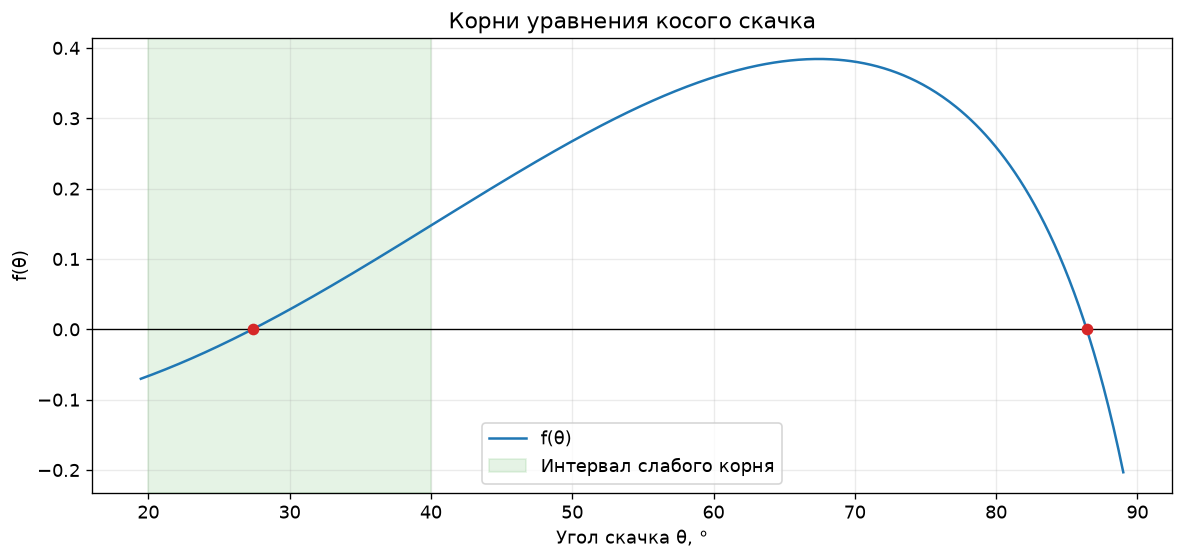

In [4]:
theta_grid = np.linspace(math.asin(1 / M1) + 1e-5, math.radians(89), 600)
fig, ax = plt.subplots()
ax.plot(np.degrees(theta_grid), [f(value) for value in theta_grid], label='f(θ)')
ax.axhline(0, color='black', linewidth=0.8)
ax.axvspan(20, 40, color='tab:green', alpha=0.12, label='Интервал слабого корня')
ax.scatter([theta_deg, math.degrees(theta_strong)], [0, 0], color='tab:red', zorder=3)
ax.set(xlabel='Угол скачка θ, °', ylabel='f(θ)', title='Корни уравнения косого скачка')
ax.legend()
fig.tight_layout()
fig.savefig(output_path / 'root_equation.png', dpi=180)
plt.show()

## 3. Аналитические параметры за скачком

Нормальная к скачку компонента числа Маха равна $M_{n1}=M_1\sin\theta$.
Из соотношений Рэнкина — Гюгонио:

$$
\begin{aligned}
\frac{p_2}{p_1}&=1+\frac{2\gamma}{\gamma+1}(M_{n1}^2-1),\\
\frac{\rho_2}{\rho_1}&=\frac{(\gamma+1)M_{n1}^2}{2+(\gamma-1)M_{n1}^2},\\
\frac{T_2}{T_1}&=\frac{p_2/p_1}{\rho_2/\rho_1},\qquad
\rho_1=\frac{p_1}{RT_1},\\
M_{n2}^2&=\frac{1+\frac{\gamma-1}{2}M_{n1}^2}
{\gamma M_{n1}^2-\frac{\gamma-1}{2}},\qquad
M_2=\frac{M_{n2}}{\sin(\theta-\beta)}.
\end{aligned}
$$

В методичке энтропия определяется с условно нулевыми константами. Чтобы аргумент
логарифма был безразмерным, это можно записать как

$$
S=c_v\ln\!\left[\frac{p/p_*}{(\rho/\rho_*)^\gamma}\right],\qquad
p_*=1\,\mathrm{Pa},\quad \rho_*=1\,\mathrm{kg/m^3}.
$$

Такой выбор воспроизводит численный вид $S=c_v\ln(p/\rho^\gamma)$ при подстановке
числовых значений в СИ. Это условная шкала, а не абсолютная энтропия.
Физически значимое приращение не зависит от выбора нуля:

$$
\Delta S=S_2-S_1=c_v\ln\!\left[\frac{p_2/p_1}{(\rho_2/\rho_1)^\gamma}\right]>0.
$$

In [5]:
Mn1 = M1 * math.sin(theta)
pressure_ratio = 1 + 2 * kappa / (kappa + 1) * (Mn1**2 - 1)
density_ratio = (kappa + 1) * Mn1**2 / (2 + (kappa - 1) * Mn1**2)
temperature_ratio = pressure_ratio / density_ratio

rho1 = p1 / (R * T1)
p2 = p1 * pressure_ratio
rho2 = rho1 * density_ratio
T2 = T1 * temperature_ratio
Mn2 = math.sqrt((1 + (kappa - 1) * Mn1**2 / 2)
                / (kappa * Mn1**2 - (kappa - 1) / 2))
M2 = Mn2 / math.sin(theta - beta)
S1 = cv * math.log(p1 / rho1**kappa)
S2 = cv * math.log(p2 / rho2**kappa)
delta_S = cv * math.log(pressure_ratio / density_ratio**kappa)

analytic = {
    'shock_deg': theta_deg, 'p2_Pa': p2, 'T2_K': T2,
    'rho1_kg_m3': rho1, 'rho2_kg_m3': rho2, 'M2': M2,
    'S1_conventional_J_kgK': S1, 'S2_conventional_J_kgK': S2,
    'deltaS_J_kgK': delta_S,
}

display(pd.DataFrame({
    'Параметр': ['p, Па', 'T, К', 'ρ, кг/м³', 'M', 'S, Дж/(кг·К)'],
    'Перед скачком': [p1, T1, rho1, M1, S1],
    'За скачком': [p2, T2, rho2, M2, S2],
}).style.format({'Перед скачком': '{:.9g}', 'За скачком': '{:.9g}'}).hide(axis='index'))
display(Math(r'\Delta S_{\mathrm{theory}} = ' + f'{delta_S:.8f}'
             + r'\,\mathrm{J/(kg\,K)} > 0'))

Параметр,Перед скачком,За скачком
"p, Па",75000,154085.411
"T, К",288,357.60442
"ρ, кг/м³",0.907375145,1.50133202
M,3,2.50500068
"S, Дж/(кг·К)",8151.74883,8162.54442


<IPython.core.display.Math object>

### Контроль аналитического решения

Проверяем исходное уравнение для угла, сохранение температуры торможения
$T_0=T\left(1+\frac{\gamma-1}{2}M^2\right)$ и альтернативную запись из методики:

$$
\begin{aligned}
u&=1-\frac{\tan(\theta-\beta)}{\tan\theta},\\
\rho_2&=\frac{\rho_1}{1-u},\\
p_2&=p_1+\rho_1u(v_1\sin\theta)^2,\\
v_1&=M_1\sqrt{\gamma RT_1}.
\end{aligned}
$$

Кроме того, сравниваем вычисления с сохранённым аналитическим эталоном отчёта.
Проверки выполняются до округления; число знаков в выводе не задаёт физическую точность CFD.

In [6]:
theta_beta_residual = (math.tan(beta)
    - 2 / math.tan(theta) * (M1**2 * math.sin(theta)**2 - 1)
    / (M1**2 * (kappa + math.cos(2 * theta)) + 2))
u = 1 - math.tan(theta - beta) / math.tan(theta)
v1 = M1 * math.sqrt(kappa * R * T1)
p2_alternative = p1 + rho1 * u * (v1 * math.sin(theta))**2
rho2_alternative = rho1 / (1 - u)
T01 = T1 * (1 + (kappa - 1) * M1**2 / 2)
T02 = T2 * (1 + (kappa - 1) * M2**2 / 2)

assert abs(theta_beta_residual) < 1e-10
np.testing.assert_allclose([p2, rho2, T01, delta_S],
                          [p2_alternative, rho2_alternative, T02, S2 - S1], rtol=1e-9)
assert delta_S > 0 and M2 > 1
reference = read_json('reference.json')
for name, value in analytic.items():
    np.testing.assert_allclose(value, reference[name], rtol=1e-9, atol=1e-9)

display(Math(r'T_{01}=T_{02}=' + f'{T01:.3f}' + r'\,\mathrm{K}'))
print('Уравнение угла, альтернативные формулы, T₀ и эталон отчёта: проверено.')

<IPython.core.display.Math object>

Уравнение угла, альтернативные формулы, T₀ и эталон отчёта: проверено.


## 4. Геометрия, сетка и параметры расчёта

Длина области равна $1.05\,\mathrm{m}$; вершина клина находится в
$(0.05;0;0)\,\mathrm{m}$. Толщина области $0.01\,\mathrm{m}$;
по толщине построен один слой ячеек. Расчёт выполнен в объёмной постановке,
геометрия и ожидаемое течение соответствуют плоскому обтеканию клина.
Высота верхней границы выбрана по теоретическому углу скачка:

$$H=1\,\mathrm{m}\cdot\tan\theta\approx0.51796755\,\mathrm{m}.$$

Сетка содержит **19 378 ячеек и 39 364 узла**. Использованы ламинарная модель совершенного
газа, $\mathrm{CFL}=0.4$, локальный шаг по времени, градиенты Green–Gauss,
максимум **20 000 итераций**. Температура стенки в настройках — $300\,\mathrm{K}$,
давление на выходе — $101325\,\mathrm{Pa}$.

Надпись WLSQ(2) в настройках относится ко вторым производным модели турбулентности,
которая в данном ламинарном расчёте отключена. Она не доказывает второй порядок
точности всей схемы.

**Сохранённая трёхмерная геометрия в Inventor.**

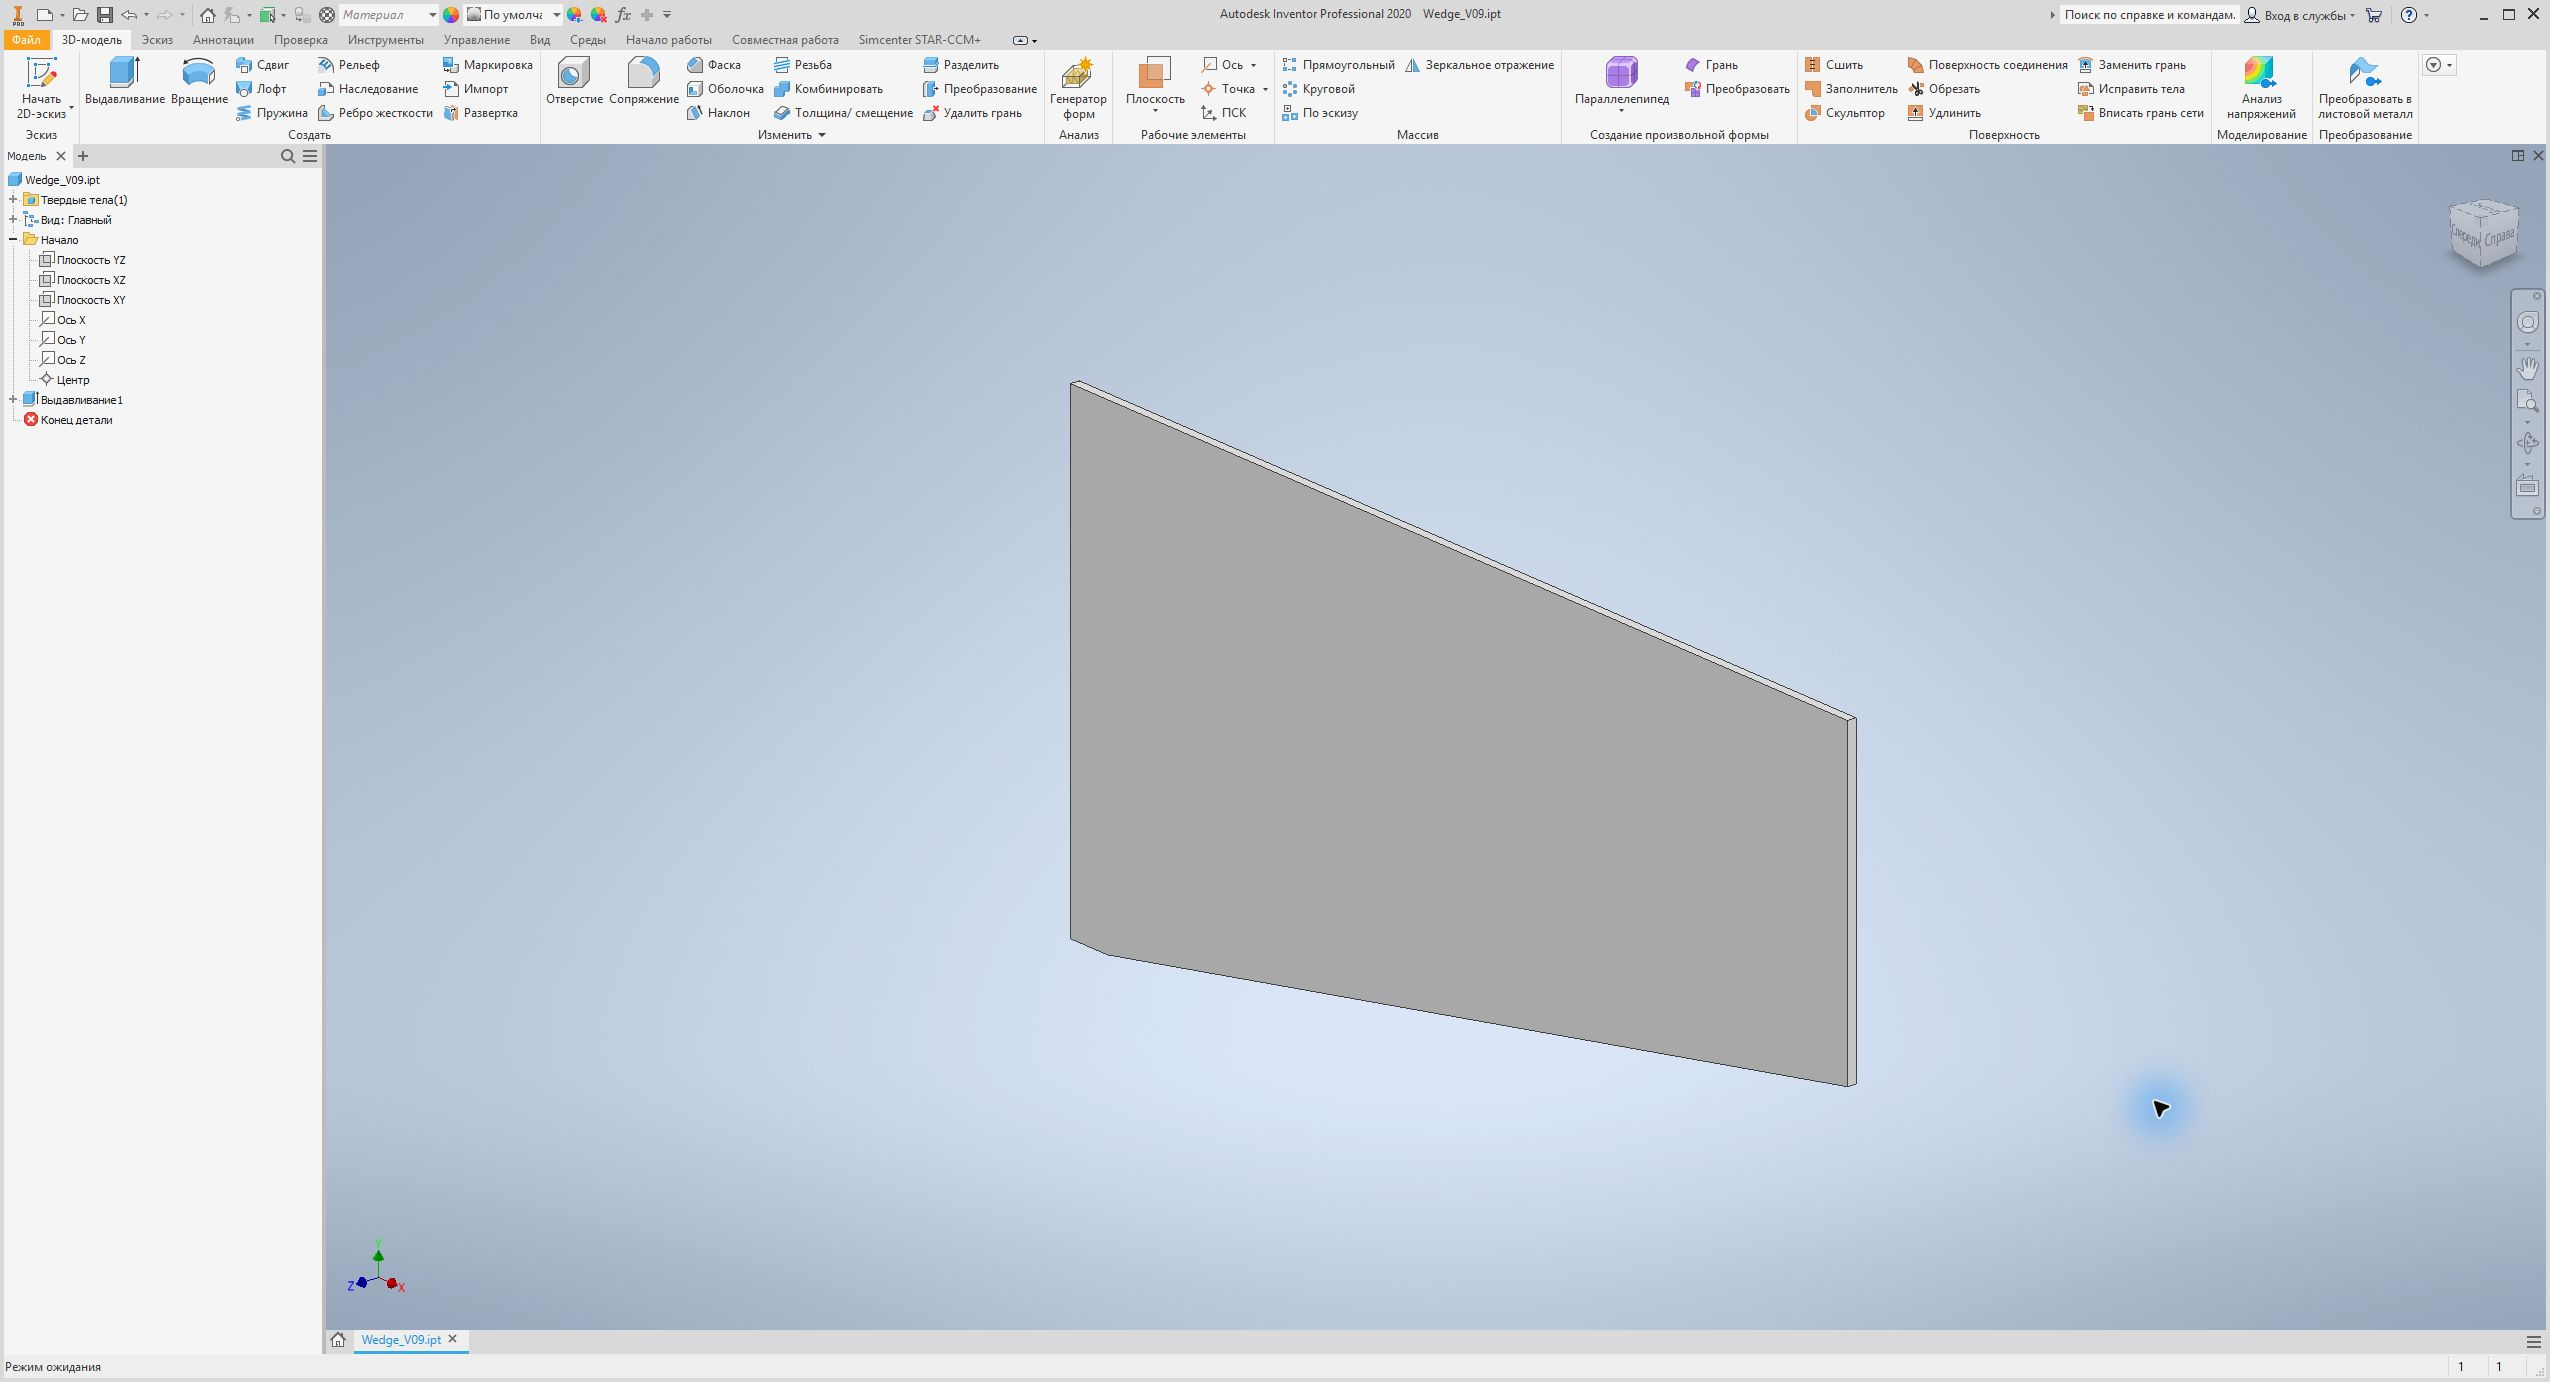

**Сохранённый вид расчётной сетки.**

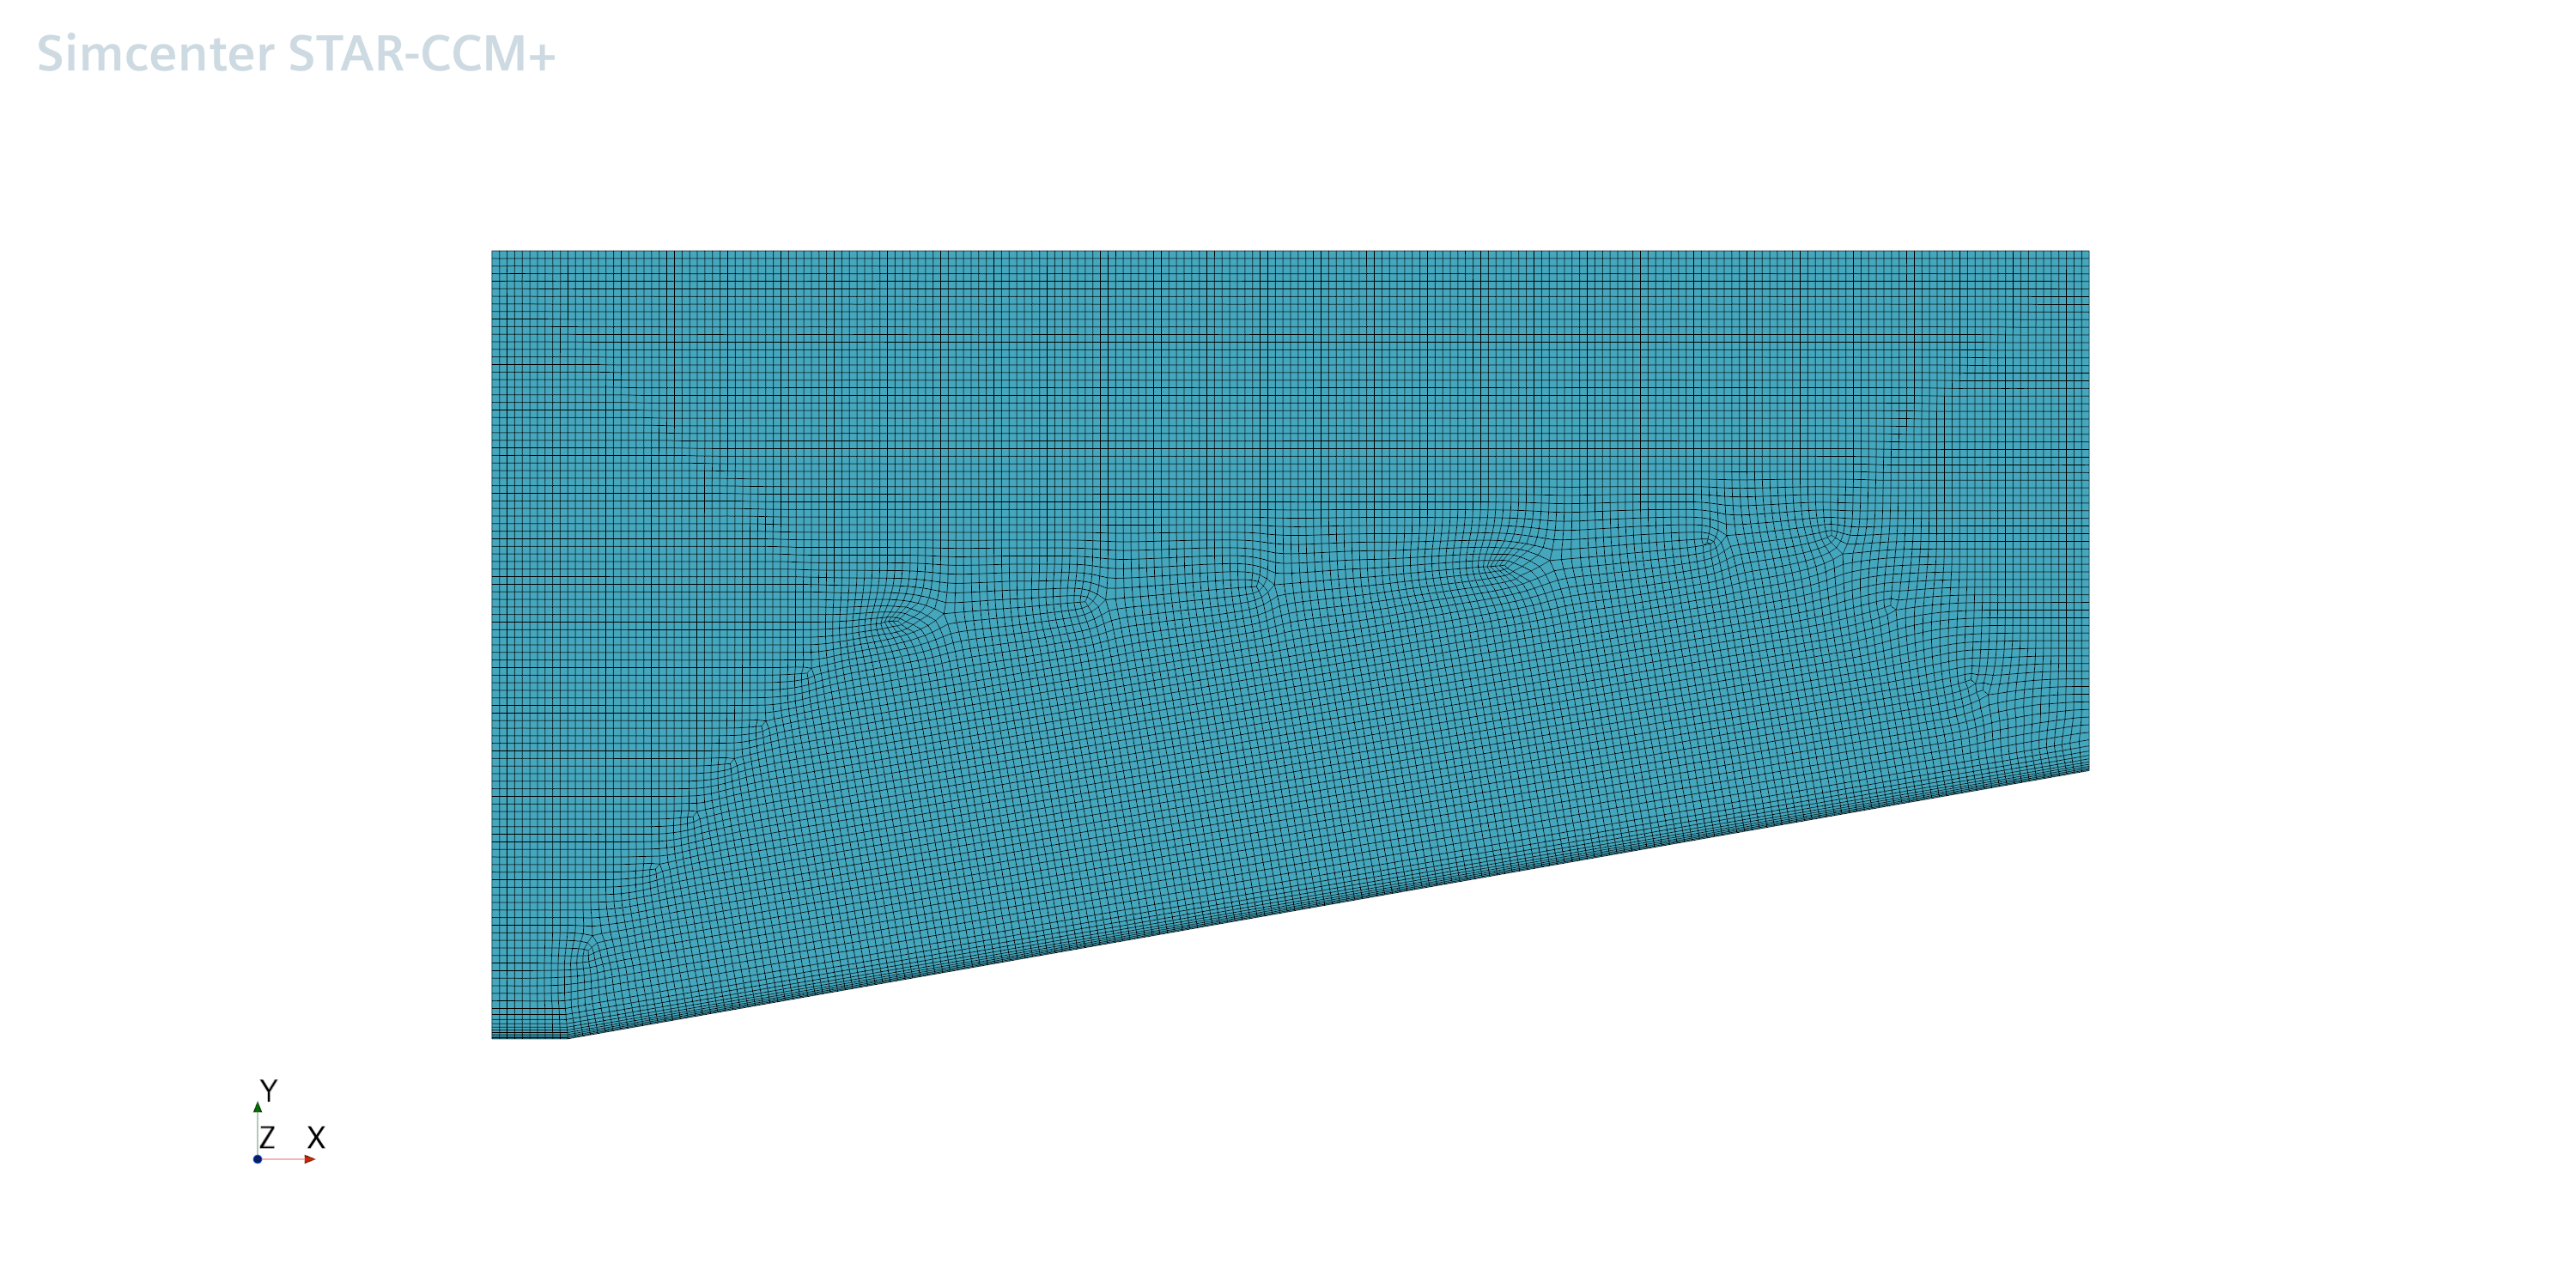

In [7]:
display(Markdown('**Сохранённая трёхмерная геометрия в Inventor.**'))
display(Image(filename=str(figures_path / 'stage_08.png'), width=1000))
display(Markdown('**Сохранённый вид расчётной сетки.**'))
display(Image(filename=str(figures_path / 'Mesh_V09.png'), width=1000))

## 5. Чтение и проверка исходных полей

Файл `volume.dat` — собственный экспорт расчёта в формате Tecplot FEBRICK/BLOCK.
Координаты заданы в узлах, 11 переменных течения — в центрах ячеек.
Ниже проверяются структура файла, индексы связности, размеры области и положительность
$p$, $\rho$, $T$. Энтропия рассчитывается по той же условной шкале, что и в отчёте.

In [8]:
def read_volume(path):
    lines = path.read_text(encoding='utf-8').splitlines()
    assert lines[7].strip() == 'ZONETYPE=FEBRICK'
    assert lines[8].strip() == 'DATAPACKING=BLOCK'
    assert lines[9].strip() == 'VARLOCATION=([4-14]=CELLCENTERED)'
    nodes = int(lines[5].split('=')[1])
    cells = int(lines[6].split('=')[1])
    values = np.fromstring('\n'.join(lines[10:]), sep=' ')
    assert values.size == 3 * nodes + 11 * cells + 8 * cells
    assert np.isfinite(values).all()

    xyz = values[:3 * nodes].reshape(3, nodes).T
    names = ['VX', 'VY', 'VZ', 'P', 'RO', 'M', 'T', 'MT', 'EI', 'TU', 'Q']
    blocks = values[3 * nodes:3 * nodes + 11 * cells].reshape(11, cells)
    fields = dict(zip(names, blocks))
    connectivity_raw = values[3 * nodes + 11 * cells:]
    assert np.equal(connectivity_raw, np.floor(connectivity_raw)).all()
    connectivity = connectivity_raw.astype(np.int64).reshape(cells, 8) - 1
    assert connectivity.min() >= 0 and connectivity.max() < nodes
    centres = xyz[connectivity].mean(axis=1)
    return xyz, connectivity, centres, fields

xyz, connectivity, centres, fields = read_volume(data_path / 'volume.dat')
nodes, cells_count = len(xyz), len(connectivity)
assert (nodes, cells_count) == (39364, 19378)
for name in ['P', 'RO', 'T']:
    assert (fields[name] > 0).all()
np.testing.assert_allclose(xyz.min(axis=0), [0, 0, -0.005], atol=1e-10)
np.testing.assert_allclose(xyz.max(axis=0),
                          [1.05, reference['domain_height_mm'] / 1000, 0.005], atol=1e-10)
fields['S'] = cv * np.log(fields['P'] / fields['RO']**kappa)

display(pd.DataFrame({
    'Ось': ['x', 'y', 'z'], 'Минимум, м': xyz.min(axis=0),
    'Максимум, м': xyz.max(axis=0),
}).style.format({'Минимум, м': '{:.9g}', 'Максимум, м': '{:.9g}'}).hide(axis='index'))
print(f'Прочитано {nodes} узлов и {cells_count} ячеек; структура и геометрия проверены.')

Ось,"Минимум, м","Максимум, м"
x,-2.53745945e-16,1.05
y,0,0.517967548
z,-0.005,0.005


Прочитано 39364 узлов и 19378 ячеек; структура и геометрия проверены.


### Газовая постоянная в сохранённом решении

Из массива полей можно независимо восстановить

$$R_{\mathrm{field}}=\frac{p}{\rho T}.$$

В данном экспорте получено примерно $286.706897\,\mathrm{J/(kg\,K)}$,
тогда как в аналитическом расчёте по $c_v=717.5\,\mathrm{J/(kg\,K)}$ используется
$R=287\,\mathrm{J/(kg\,K)}$. Отличие около $0.1021\%$ объясняет небольшую систематическую
разницу плотности невозмущённого потока. Исходные поля не исправляются.
Сопоставление с теорией сохраняет исходные параметры методики.
Проверка числа Маха ниже использует восстановленную постоянную и скорости из того же экспорта.

In [9]:
R_values = fields['P'] / (fields['RO'] * fields['T'])
R_field = float(np.median(R_values))
R_difference_percent = abs(R_field - R) / R * 100
eos_max_error = float(np.max(np.abs(R_values / R_field - 1)))
speed = np.sqrt(fields['VX']**2 + fields['VY']**2 + fields['VZ']**2)
mach_recomputed = speed / np.sqrt(kappa * R_field * fields['T'])
mach_max_difference = float(np.max(np.abs(mach_recomputed - fields['M'])))
assert eos_max_error < 1e-9
assert mach_max_difference < 1e-4

display(Math(r'R_{\mathrm{field}}=' + f'{R_field:.9f}' + r'\,\mathrm{J/(kg\,K)}'))
display(pd.DataFrame({
    'Проверка': ['Отличие R от аналитического, %',
                'Максимальная относительная невязка p = ρRT',
                'Максимальное абсолютное отличие M'],
    'Значение': [R_difference_percent, eos_max_error, mach_max_difference],
}).style.format({'Значение': '{:.9g}'}).hide(axis='index'))

<IPython.core.display.Math object>

Проверка,Значение
"Отличие R от аналитического, %",0.102126637
Максимальная относительная невязка p = ρRT,1.00019992e-12
Максимальное абсолютное отличие M,7.54867505e-05


## 6. Поля параметров и линии тока

Ниже встроены исходные рисунки Tecplot из выполненной работы. Они сохраняются в ноутбуке
вместе с результатами выполнения и доступны при просмотре без повторного запуска.
Косая граница изменения параметров соответствует присоединённому скачку уплотнения;
за ним давление, температура, плотность и энтропия увеличиваются, число Маха уменьшается,
а поток поворачивает вдоль клина. У стенки и выходной границы картина отличается
от идеализированного однородного состояния за невязким скачком.

**Давление p, Па. За скачком давление повышается.**

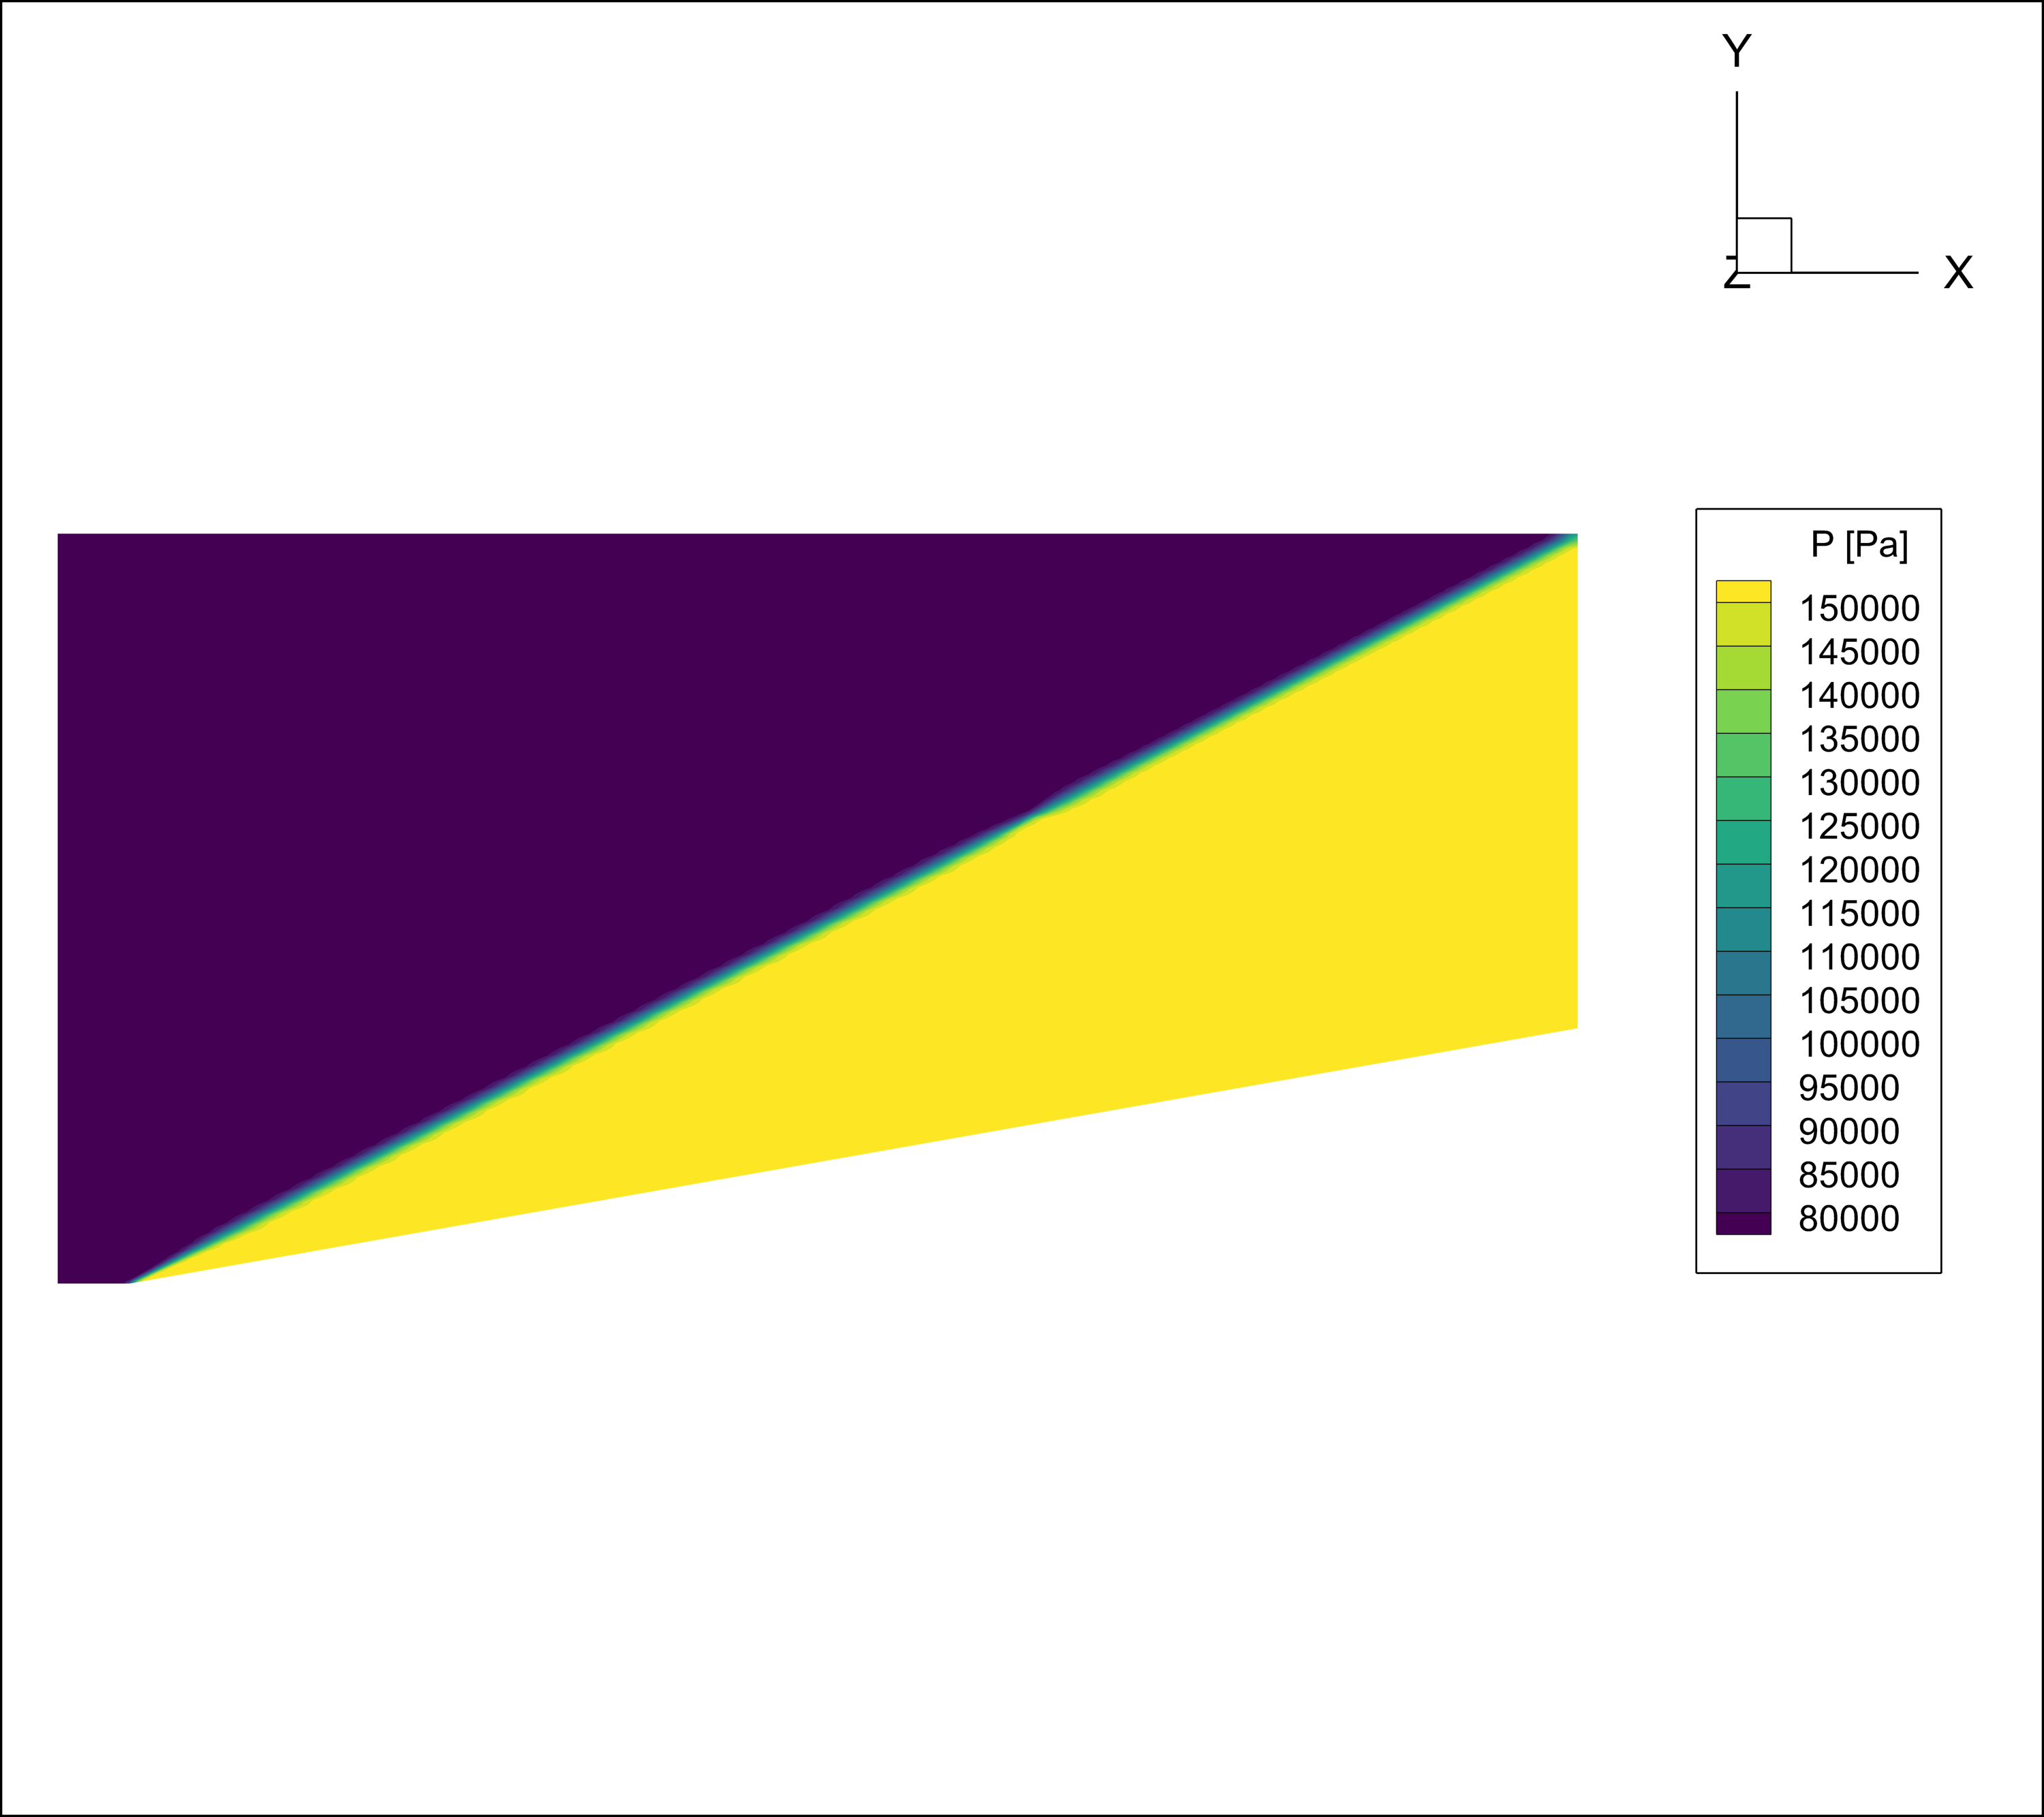

**Температура T, К. Сжатие сопровождается нагревом.**

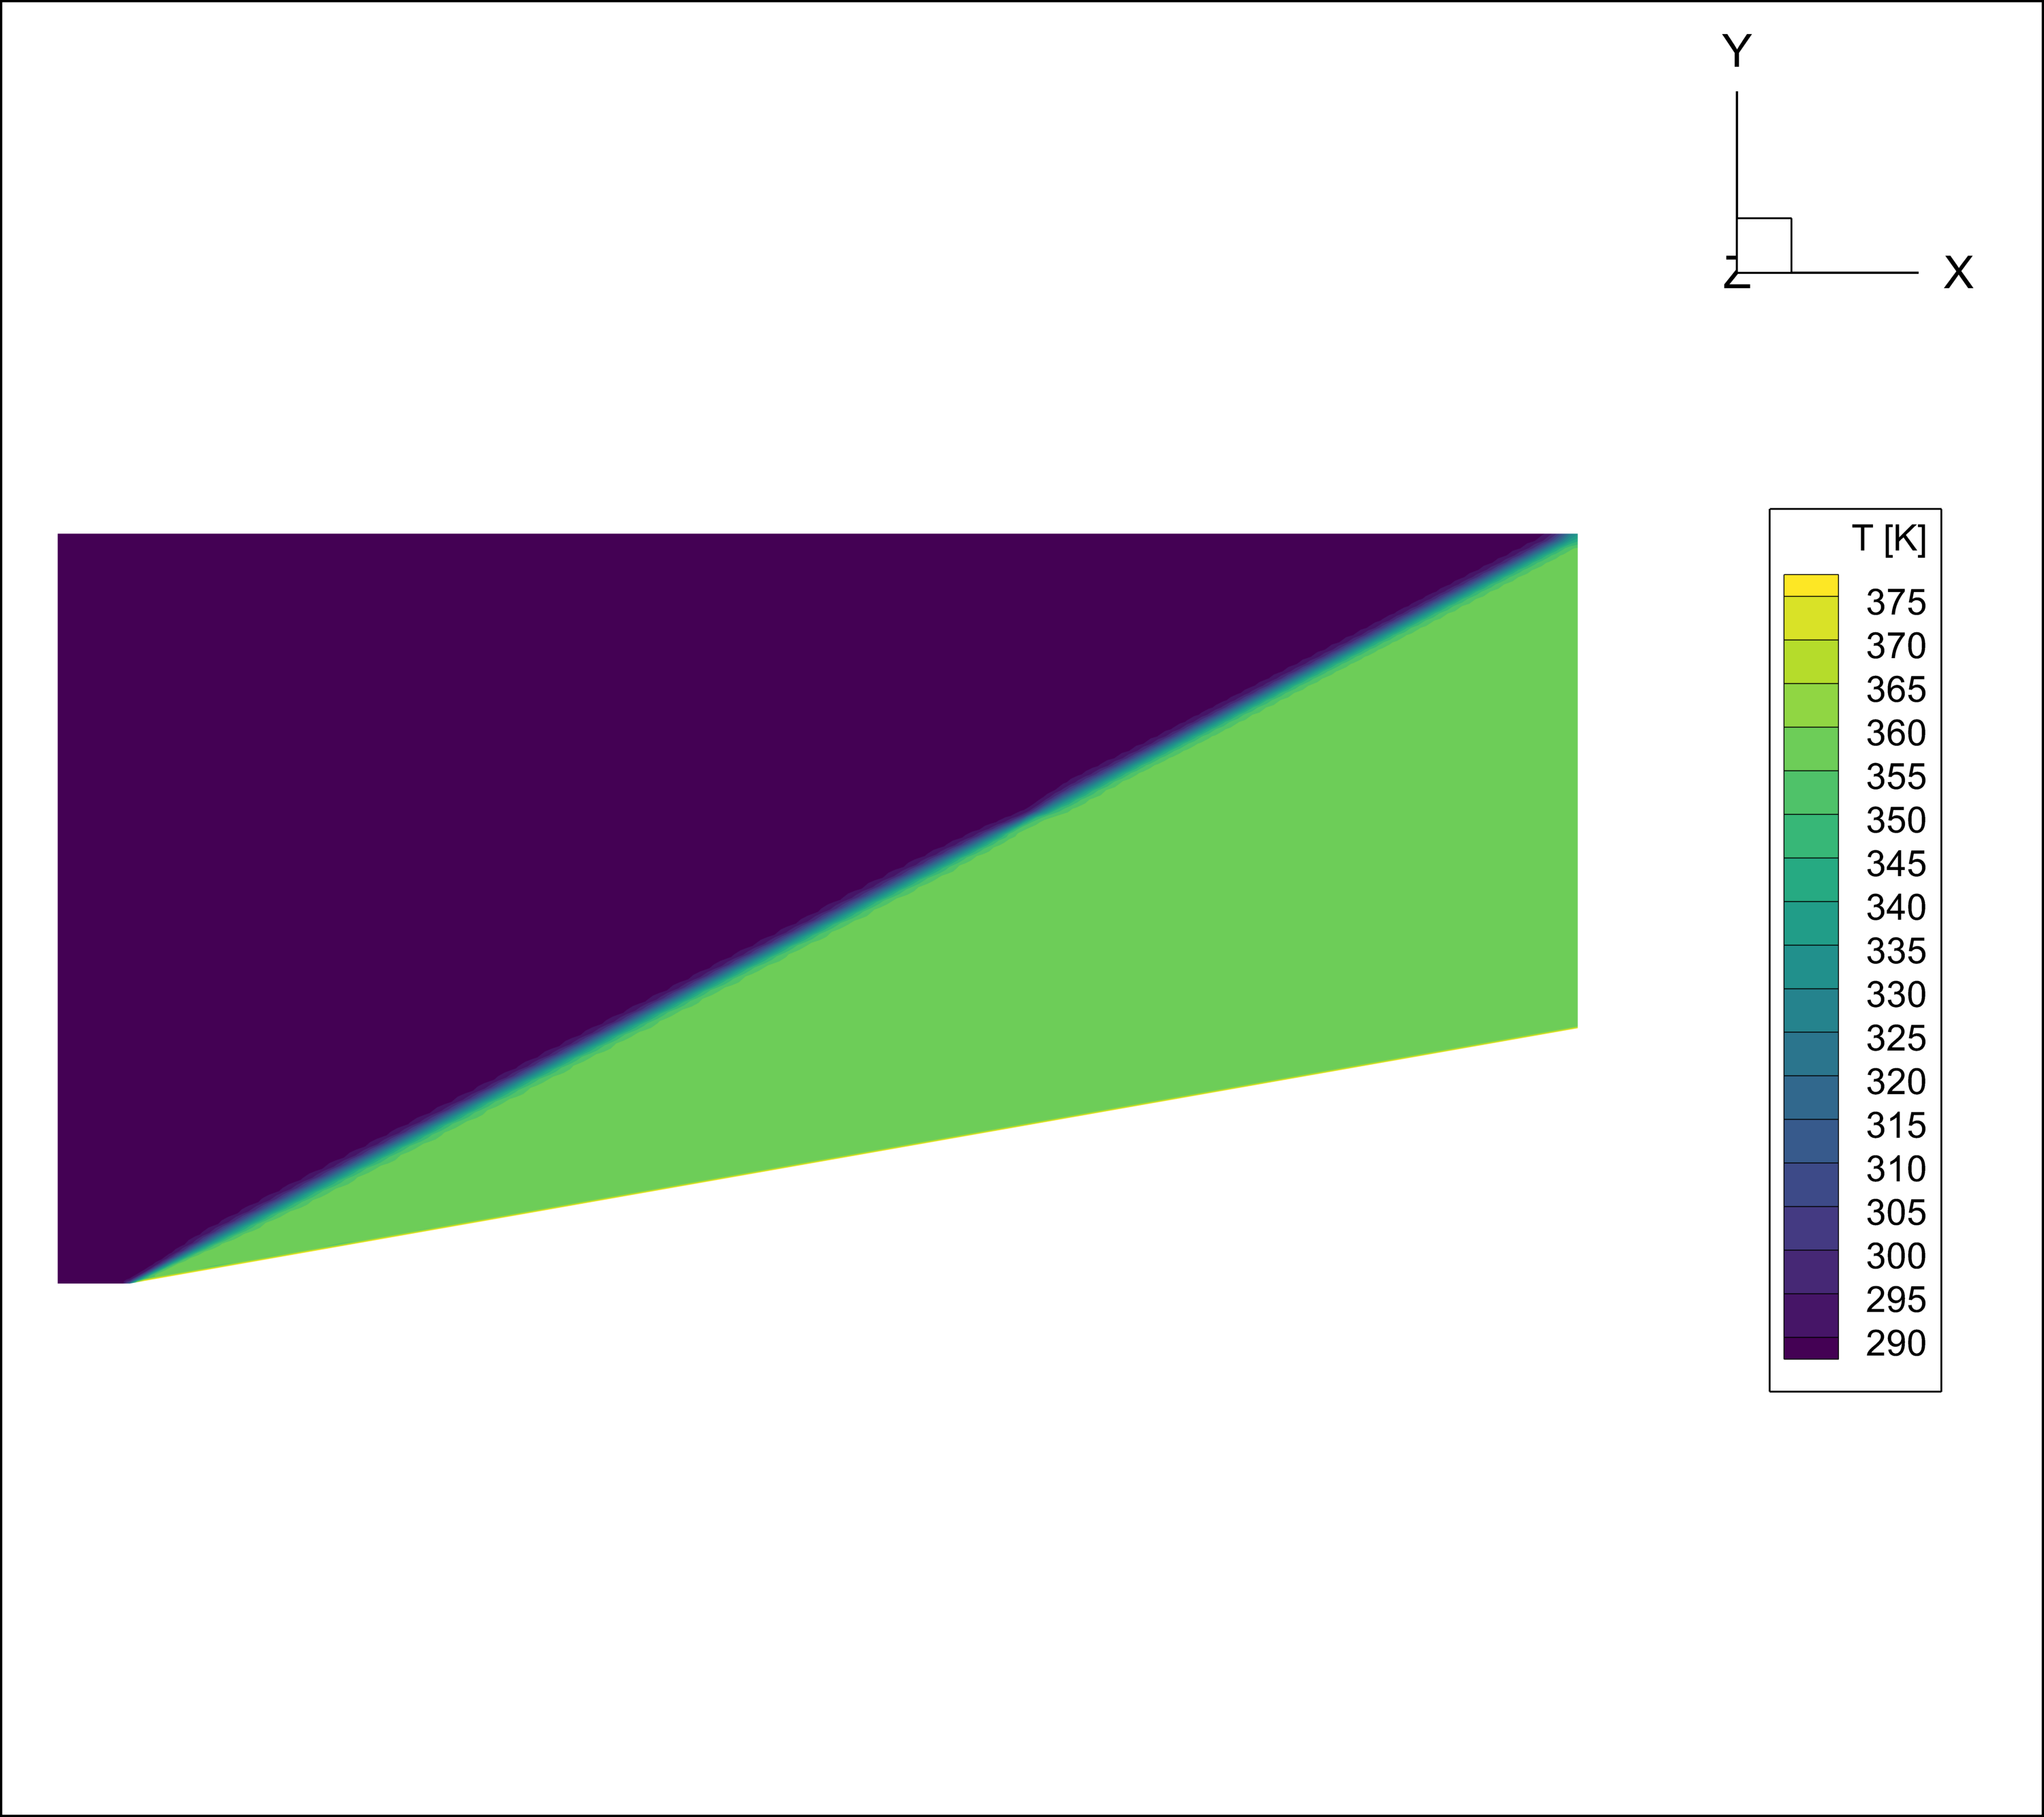

**Плотность ρ, кг/м³. Скачок соответствует сжатию газа.**

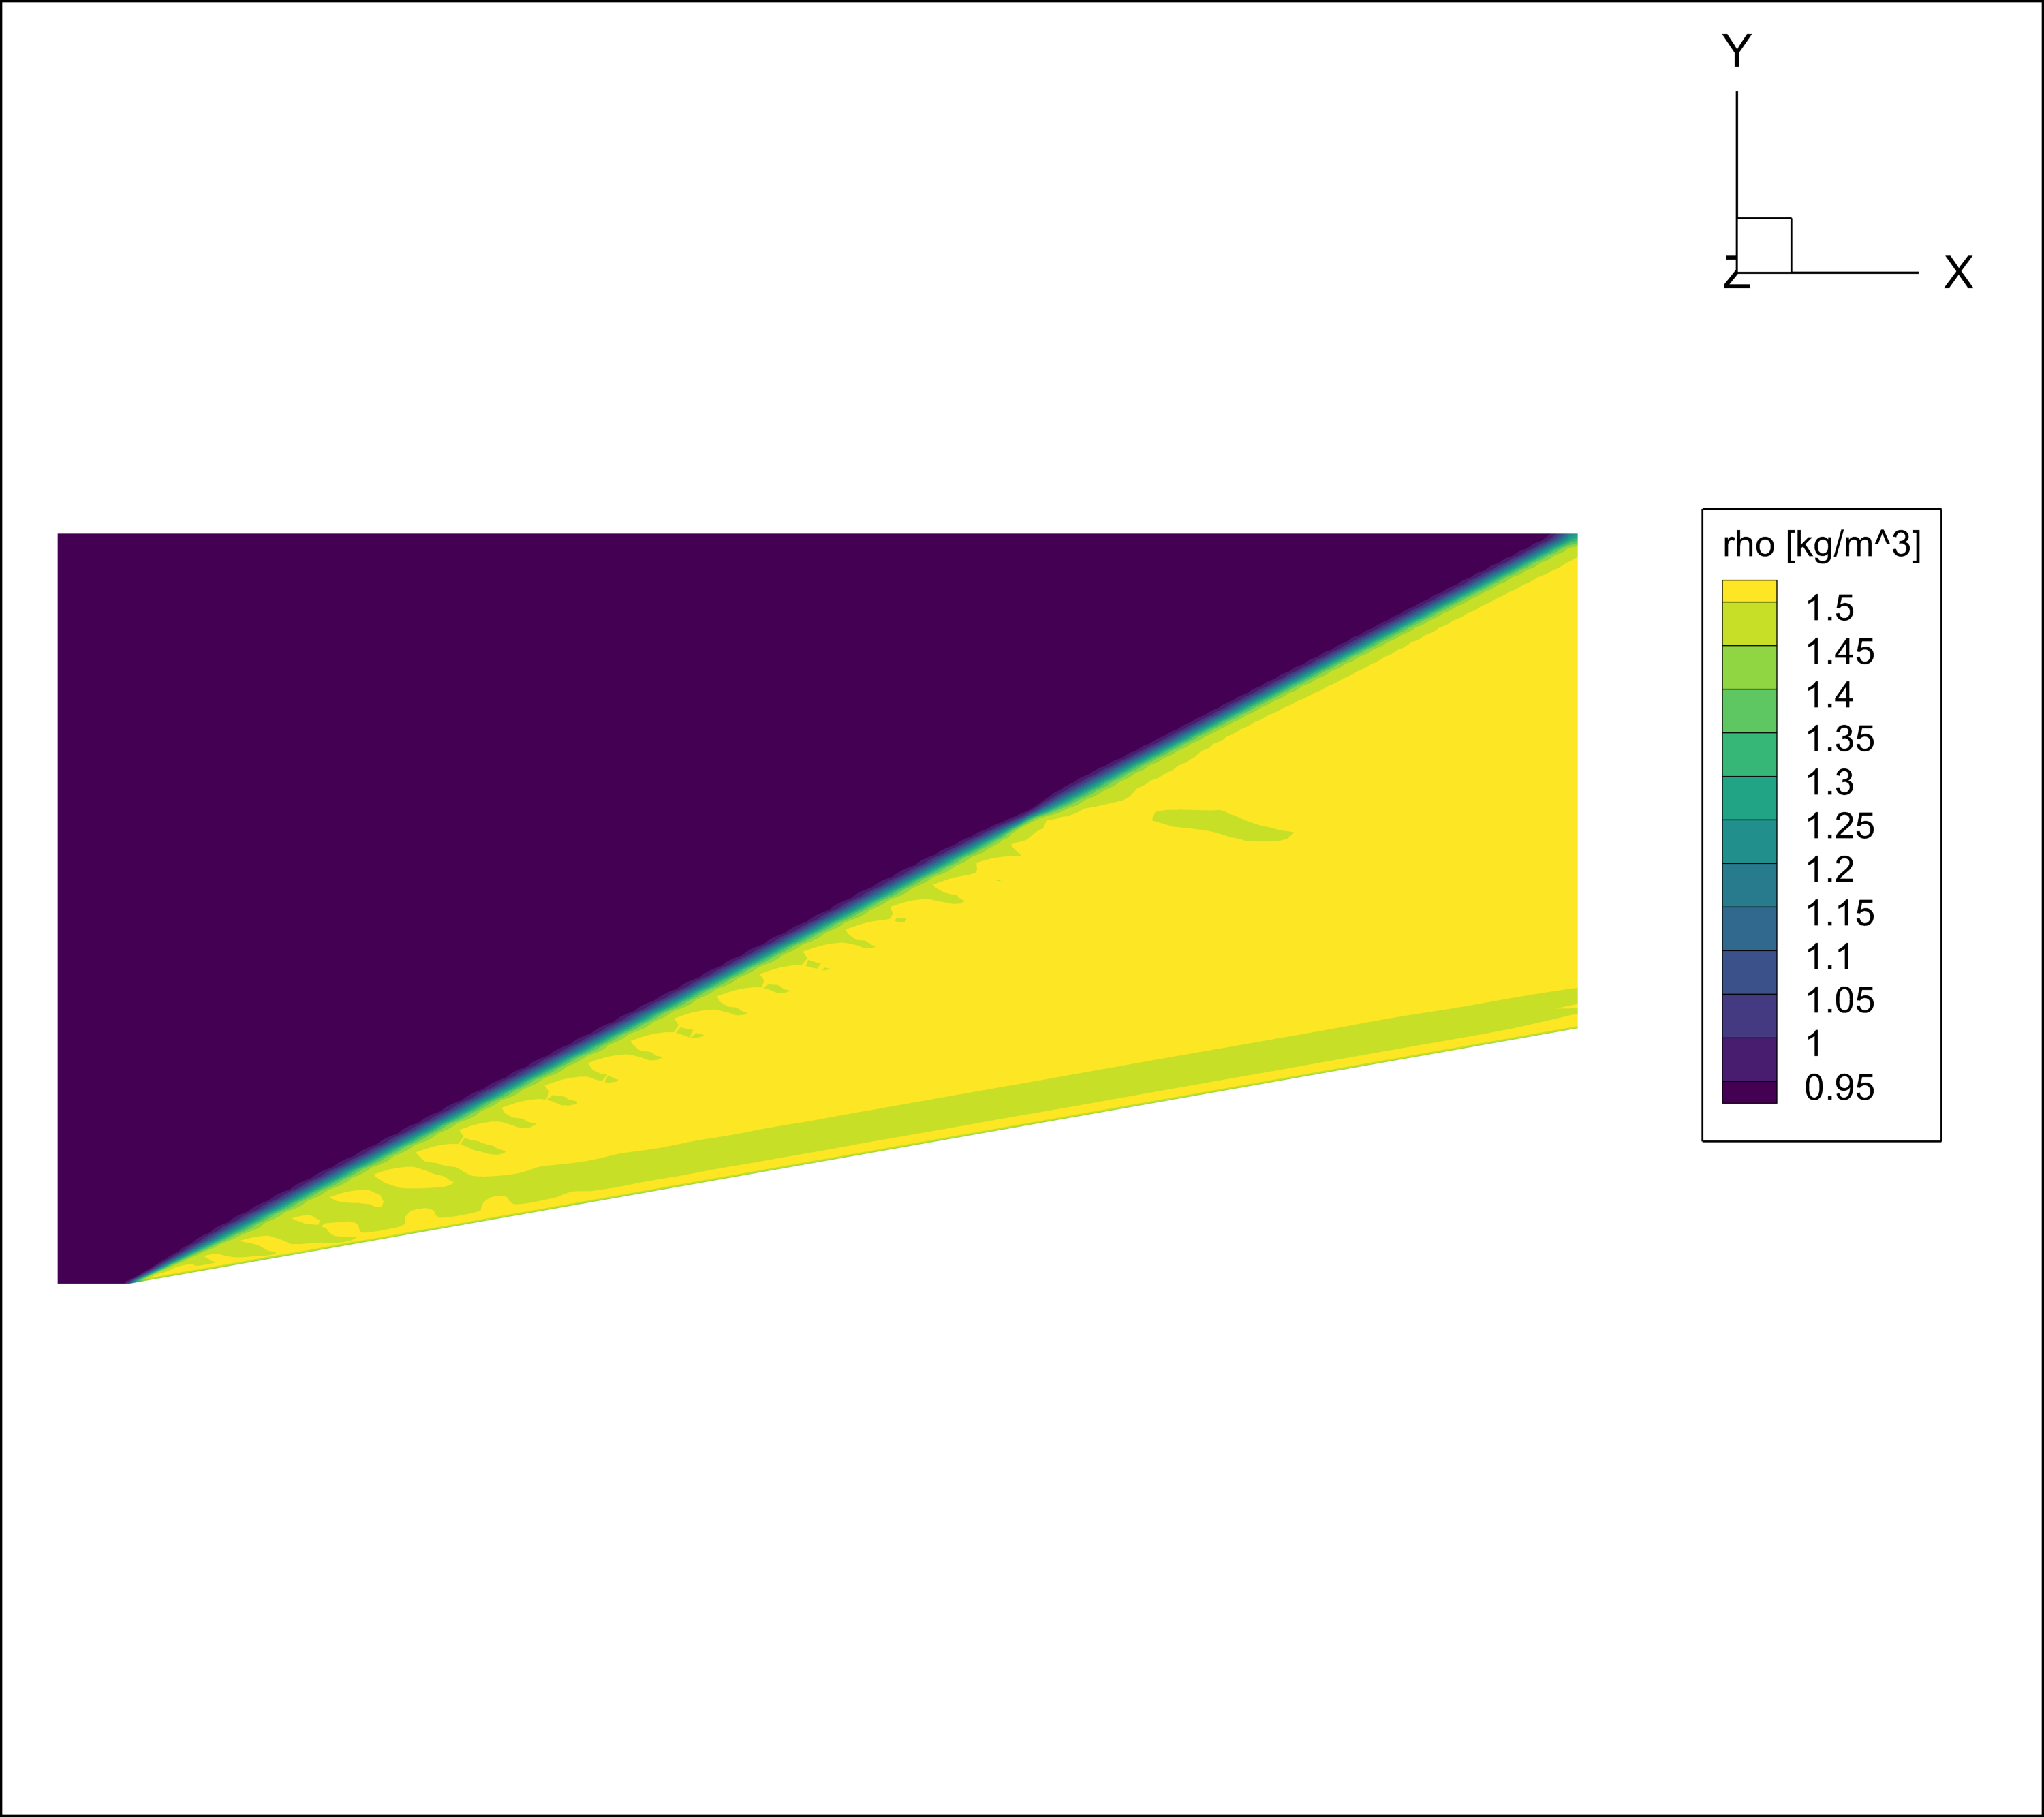

**Число Маха M, безразмерное. За слабым скачком поток остаётся сверхзвуковым.**

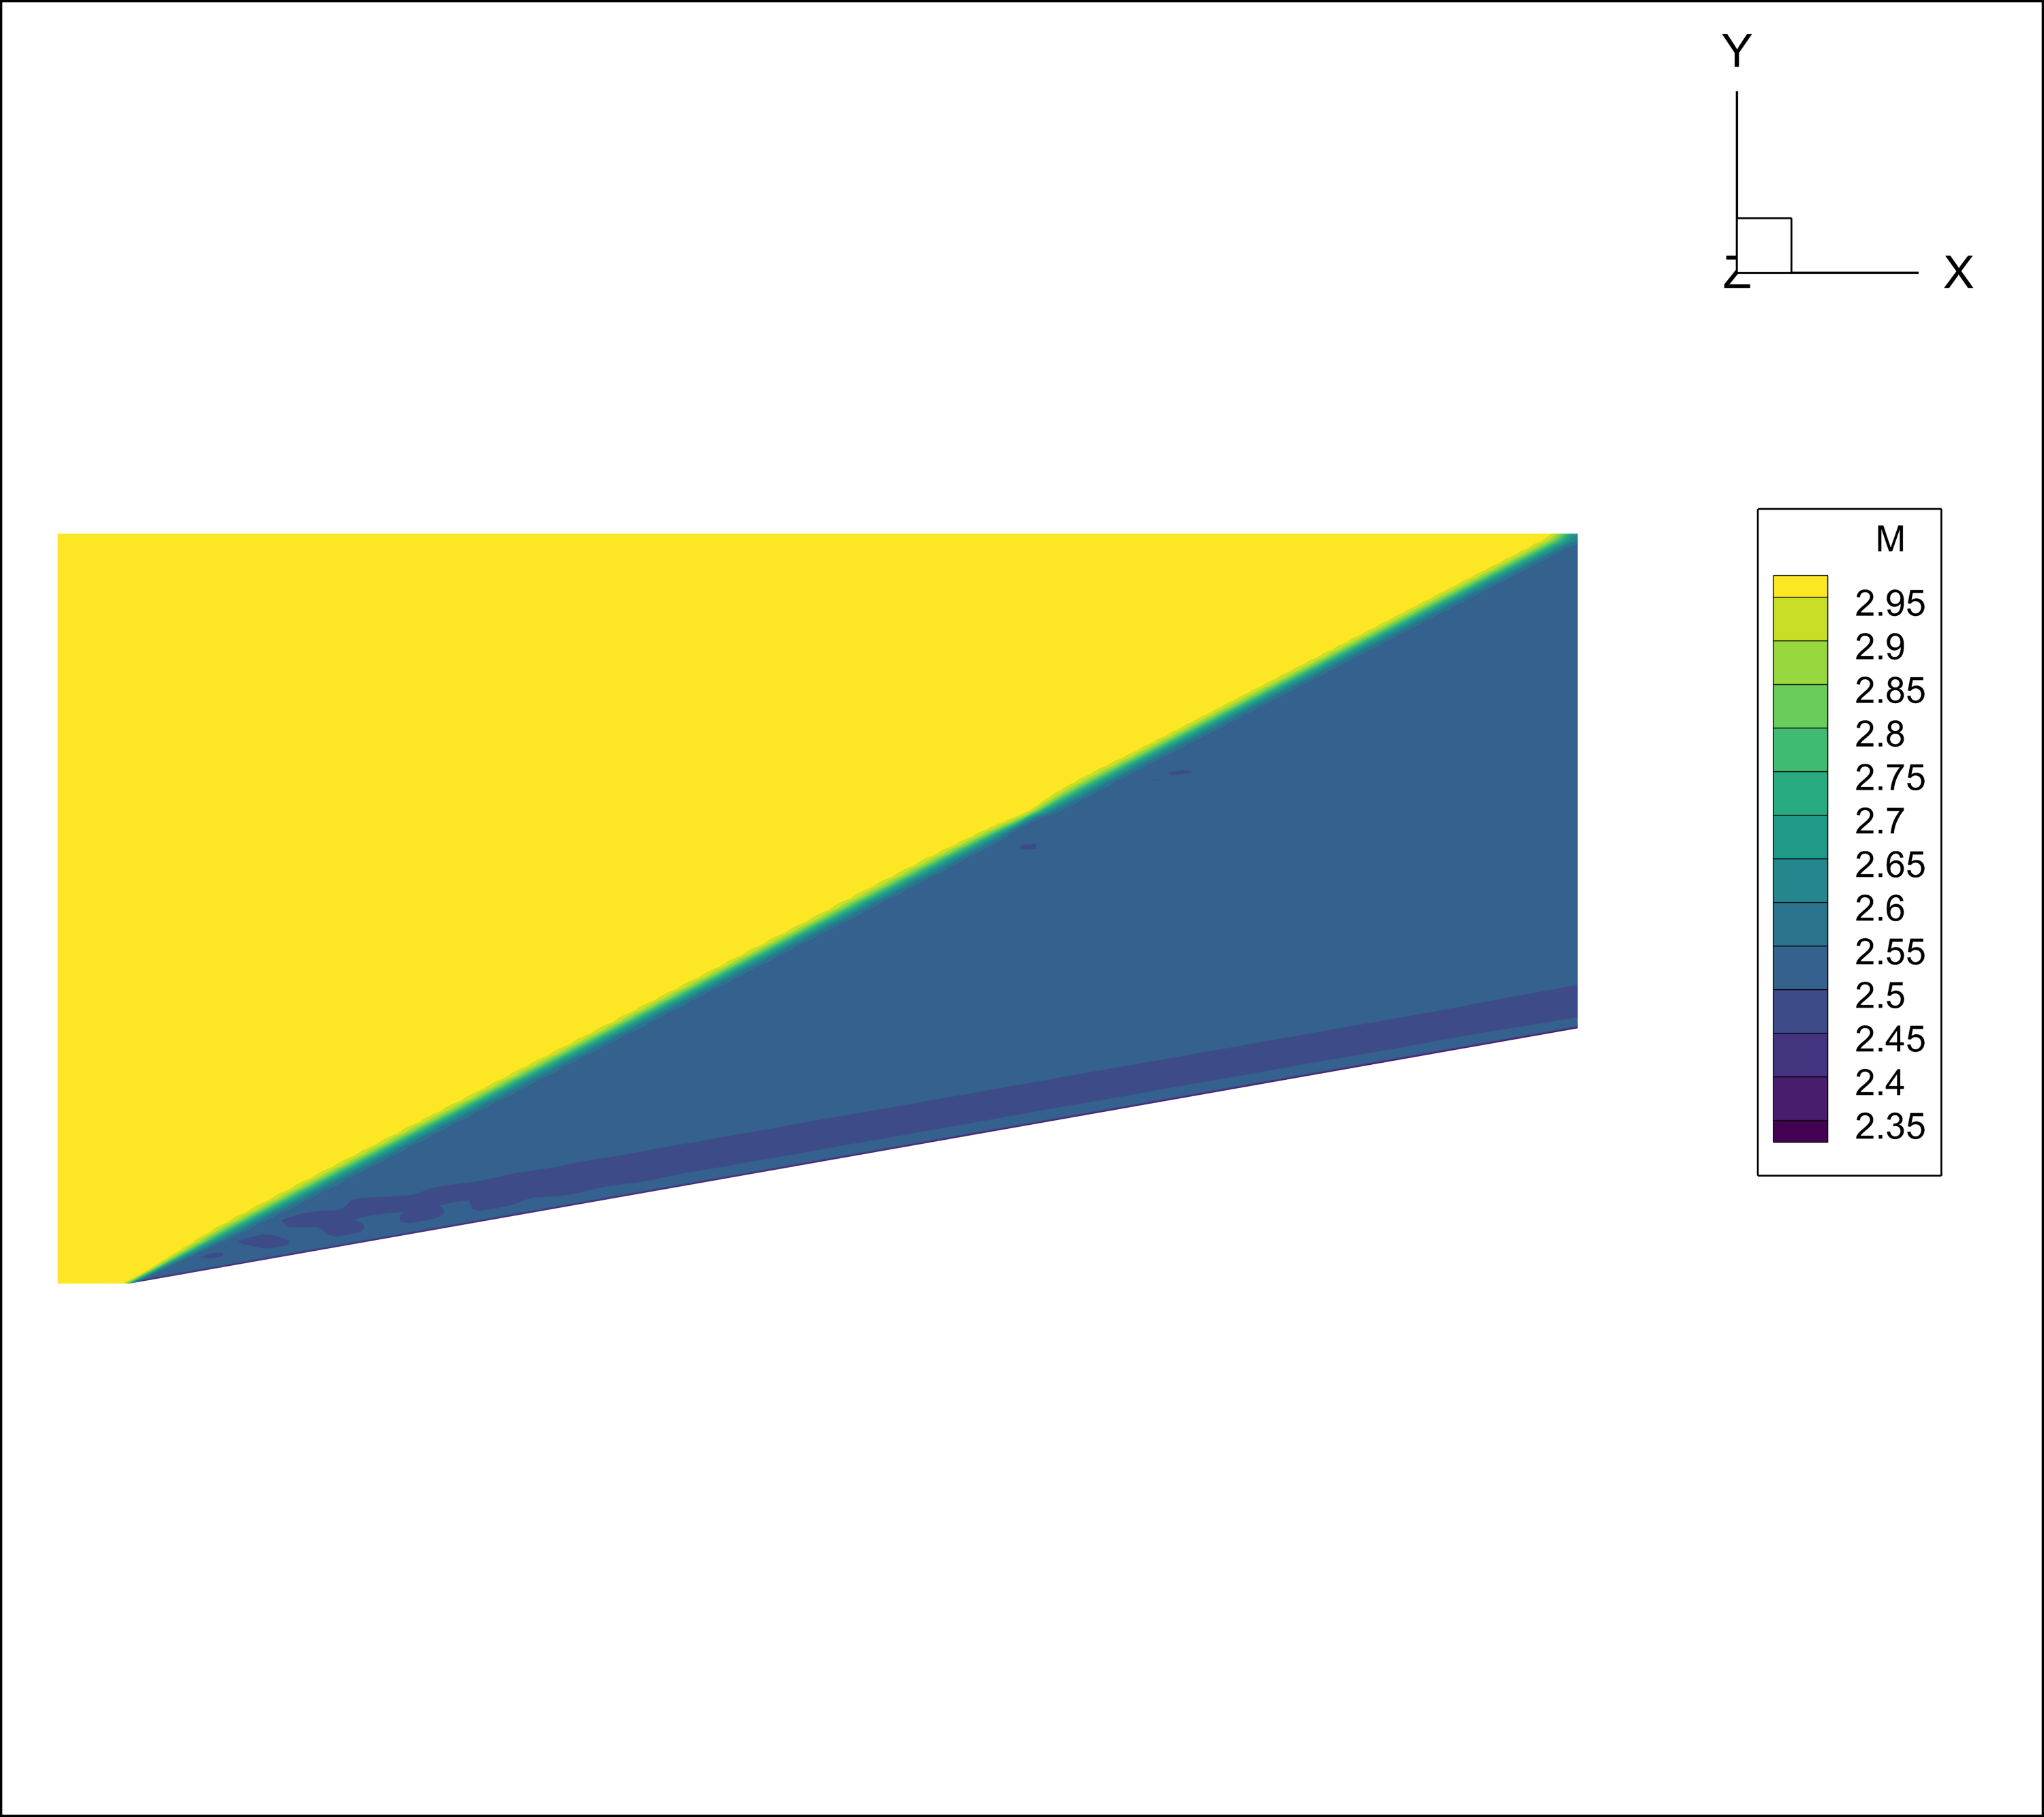

**Условная энтропия S, Дж/(кг·К). Её рост характеризует необратимость скачка.**

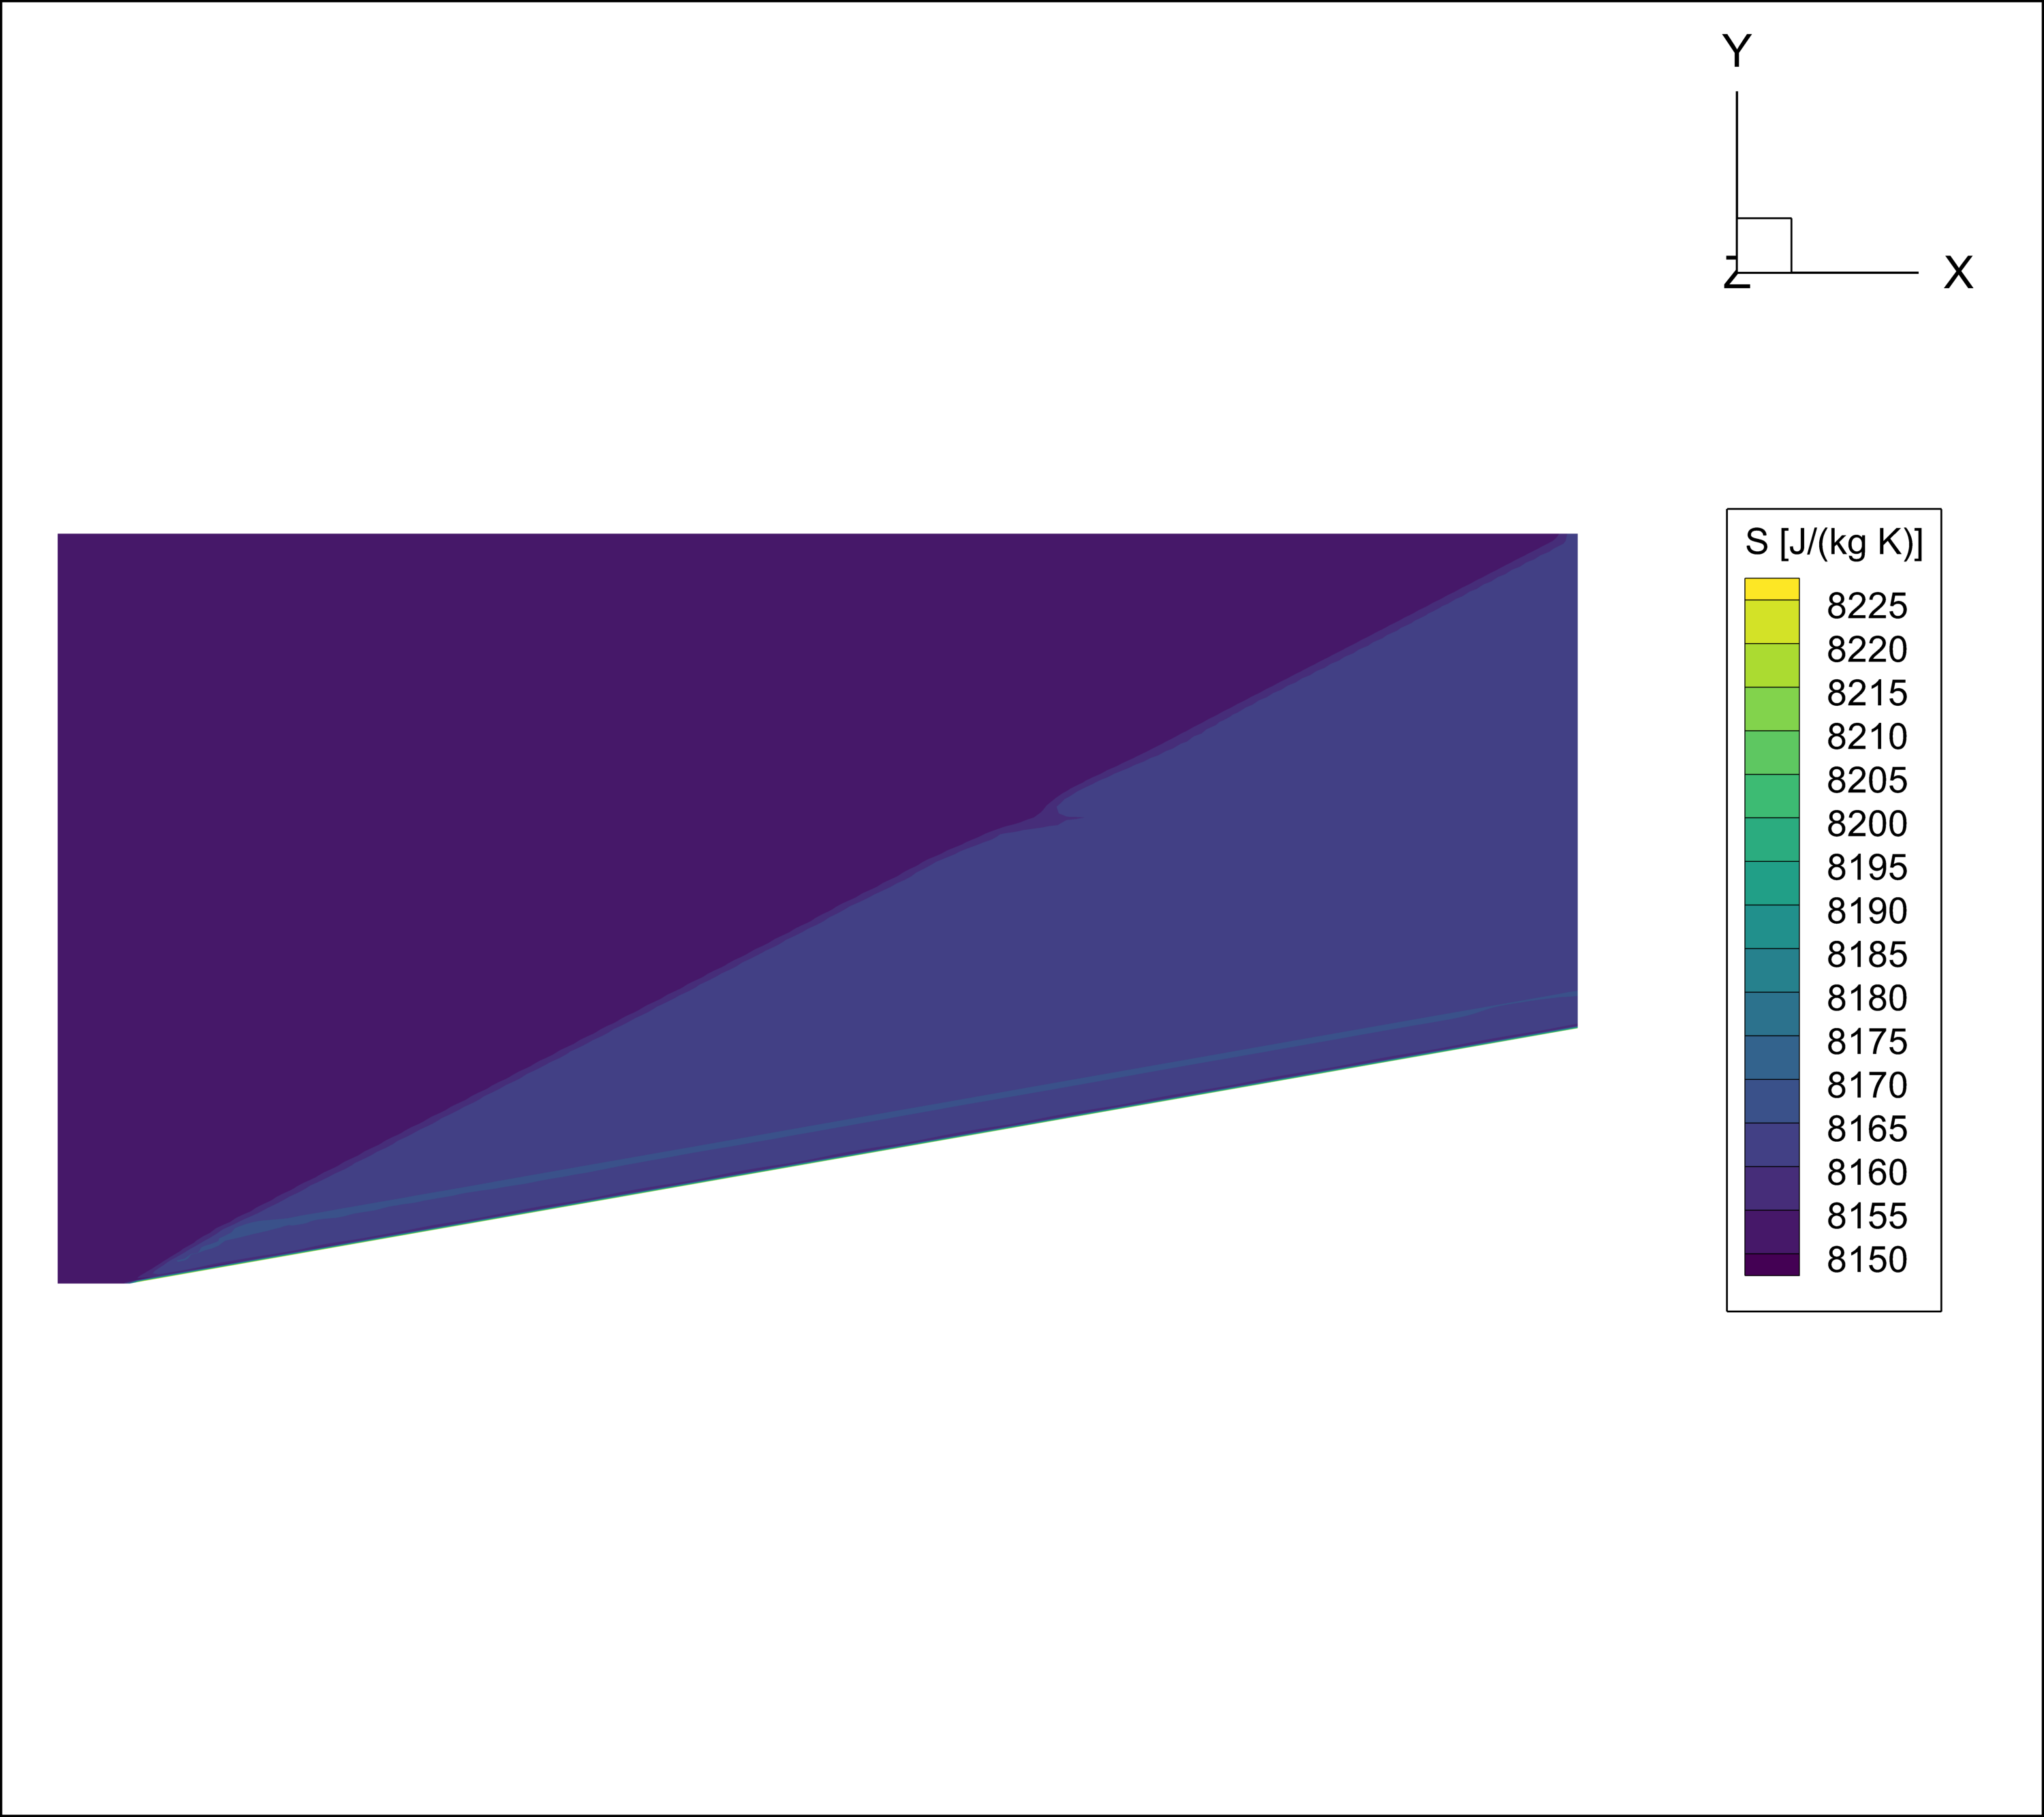

**Линии тока. После прохождения скачка поток поворачивает к поверхности клина.**

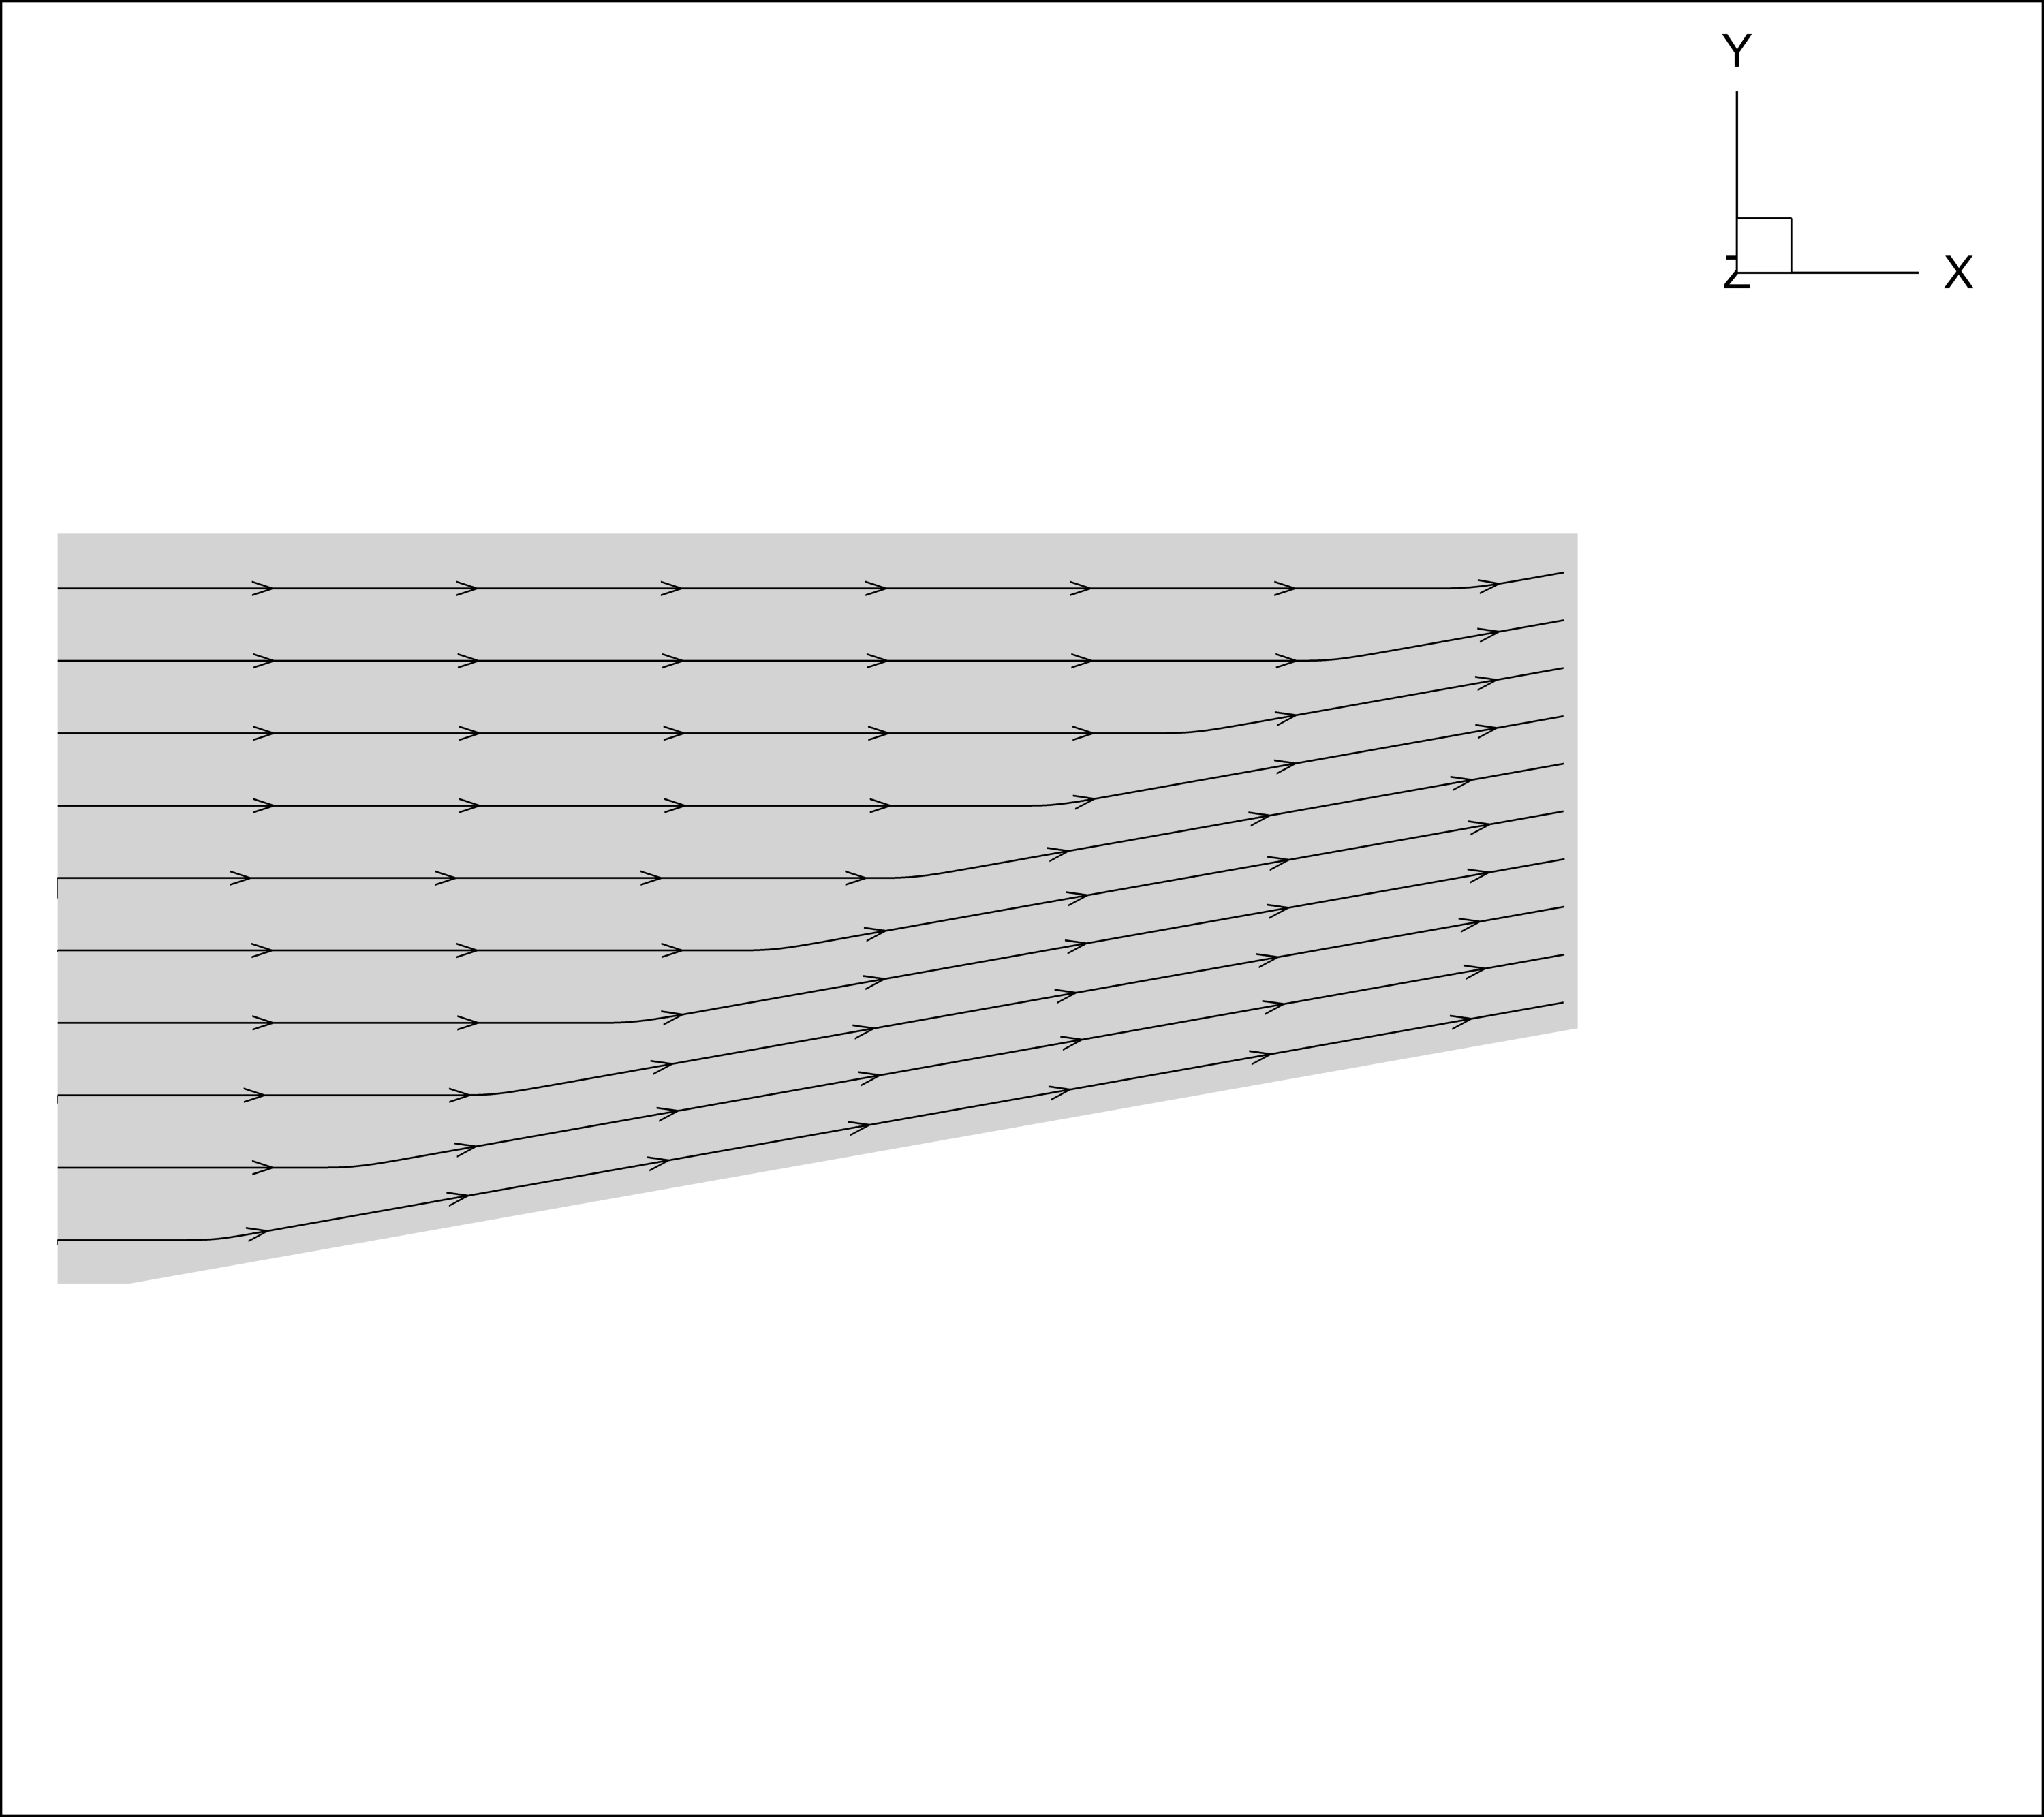

In [10]:
field_figures = [
    ('Pressure_V09.png', 'Давление p, Па. За скачком давление повышается.'),
    ('Temperature_V09.png', 'Температура T, К. Сжатие сопровождается нагревом.'),
    ('Density_V09.png', 'Плотность ρ, кг/м³. Скачок соответствует сжатию газа.'),
    ('Mach_V09.png', 'Число Маха M, безразмерное. За слабым скачком поток остаётся сверхзвуковым.'),
    ('Entropy_V09.png', 'Условная энтропия S, Дж/(кг·К). Её рост характеризует необратимость скачка.'),
    ('Streamlines_V09.png', 'Линии тока. После прохождения скачка поток поворачивает к поверхности клина.'),
]
for name, caption in field_figures:
    display(Markdown('**' + caption + '**'))
    display(Image(filename=str(figures_path / name), width=1000))

## 7. Измерение угла скачка по полю давления

Угол измеряется по численному полю независимо от аналитического результата.
Сначала берём значения давления в ближайших к контрольным точкам ячейках.
В каждом из 15 сечений $x_0\in[0.20;0.90]\,\mathrm{m}$ выбираем узкую полосу
$|x-x_0|<0.012\,\mathrm{m}$ и переходные ячейки с давлением от 15 до 85 % скачка.
По этим данным методом наименьших квадратов строим локальную аппроксимацию

$$
\begin{aligned}
p&=a(x-x_0)+by+c,\\
y_{\mathrm{shock}}(x_0)&=\frac{p_{\mathrm{mid}}-c}{b},\\
p_{\mathrm{mid}}&=\frac{p_{\mathrm{up}}+p_{\mathrm{down}}}{2}.
\end{aligned}
$$

Затем аппроксимируем полученные точки прямой $y=kx+b_0$ и вычисляем
$\theta_{\mathrm{CFD}}=\arctan k$. Такой способ определяет середину размазанного
сеткой фронта. Он не является доказательством сеточной независимости.

In [11]:
def nearest_cell(point):
    distance = np.linalg.norm(centres - np.asarray(point), axis=1)
    index = int(np.argmin(distance))
    values = {name: float(array[index]) for name, array in fields.items()}
    return index, values

up_index, up = nearest_cell([0.65, 0.42, 0])
down_index, down = nearest_cell([0.65, 0.20, 0])
x, y, pressure = centres[:, 0], centres[:, 1], fields['P']
pressure_jump = down['P'] - up['P']
pressure_middle = (down['P'] + up['P']) / 2
shock_points = []

for x0 in np.linspace(0.20, 0.90, 15):
    mask = ((np.abs(x - x0) < 0.012)
            & (pressure > up['P'] + 0.15 * pressure_jump)
            & (pressure < up['P'] + 0.85 * pressure_jump))
    assert mask.sum() >= 4
    matrix = np.column_stack([x[mask] - x0, y[mask], np.ones(mask.sum())])
    a_local, b_local, c_local = np.linalg.lstsq(matrix, pressure[mask], rcond=None)[0]
    shock_points.append([x0, (pressure_middle - c_local) / b_local, int(mask.sum())])

shock_points = np.asarray(shock_points)
slope, intercept = np.polyfit(shock_points[:, 0], shock_points[:, 1], 1)
theta_cfd = math.degrees(math.atan(slope))
line_deviation = float(np.max(np.abs(shock_points[:, 1]
                                   - (slope * shock_points[:, 0] + intercept))))
saved_points = pd.read_csv(data_path / 'shock_points.csv').to_numpy()
np.testing.assert_allclose(shock_points, saved_points, rtol=1e-10, atol=1e-10)

display(Math(r'\theta_{\mathrm{CFD}}=' + f'{theta_cfd:.8f}' + r'^\circ'))
display(Math(r'\max |y_i-(kx_i+b_0)|=' + f'{line_deviation:.8f}' + r'\,\mathrm{m}'))
display(pd.DataFrame(shock_points, columns=['x, м', 'y, м', 'Ячеек в сечении'])
        .style.format({'x, м': '{:.2f}', 'y, м': '{:.7f}', 'Ячеек в сечении': '{:.0f}'})
        .hide(axis='index'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

"x, м","y, м",Ячеек в сечении
0.20,0.0782075,7
0.25,0.1040402,8
0.30,0.1299040,8
0.35,0.1558608,7
0.40,0.1817278,8
0.45,0.2075880,9
0.50,0.2335212,7
0.55,0.2593493,7
0.60,0.2853489,9
0.65,0.3111465,12


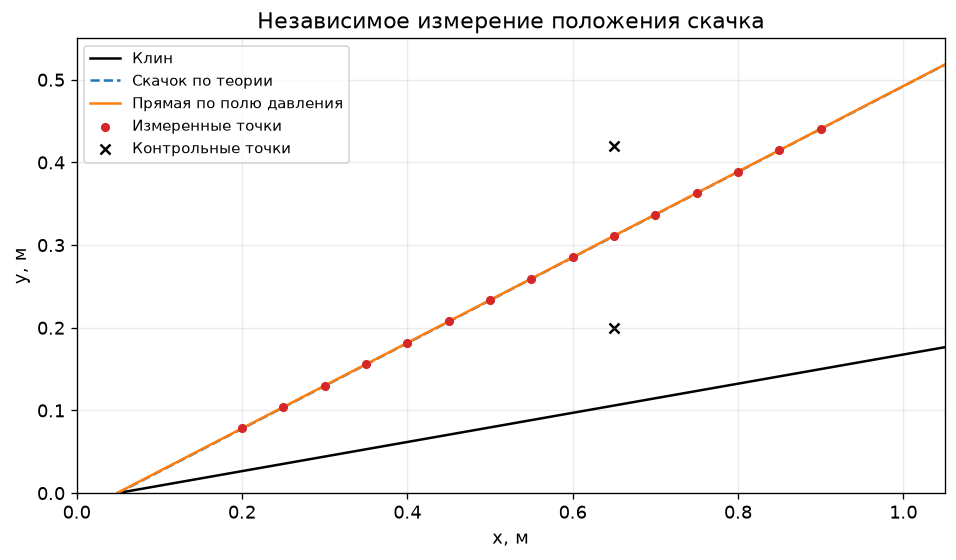

In [12]:
x_line = np.linspace(0.05, 1.05, 300)
fig, ax = plt.subplots()
ax.plot(x_line, (x_line - 0.05) * math.tan(beta), color='black', label='Клин')
ax.plot(x_line, (x_line - 0.05) * math.tan(theta), '--', label='Скачок по теории')
ax.plot(x_line, slope * x_line + intercept, label='Прямая по полю давления')
ax.scatter(shock_points[:, 0], shock_points[:, 1], s=20, color='tab:red',
           label='Измеренные точки', zorder=3)
ax.scatter([0.65, 0.65], [0.42, 0.20], marker='x', color='black', label='Контрольные точки')
ax.set(xlim=(0, 1.05), ylim=(0, 0.55), xlabel='x, м', ylabel='y, м',
       title='Независимое измерение положения скачка')
ax.set_aspect('equal', adjustable='box')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
fig.savefig(output_path / 'shock_measurement.png', dpi=180)
plt.show()

## 8. Контрольные точки и сравнение с теорией

В отчёте использованы сохранённые значения **Tecplot Probe At** с включённой
интерполяцией внутри объёма. Точка перед скачком:
$(0.65;0.42;0)\,\mathrm{m}$; точка за скачком: $(0.65;0.20;0)\,\mathrm{m}$.
Показания зафиксированы на оригинальных скриншотах ниже и в `probe_values.json`.
Файл содержит именно показания Probe At; алгоритм интерполяции Tecplot здесь не воспроизводится.

Относительная погрешность вычисляется по неокруглённым значениям:

$$\delta_q=\frac{|q_{\mathrm{CFD}}-q_{\mathrm{theory}}|}{|q_{\mathrm{theory}}|}\,100\%.$$

Для условного $S_2$ погрешность зависит от выбранного нуля энтропии;
поэтому дополнительно приводится более содержательное сравнение $\Delta S$.

**Probe At: точка за скачком.**

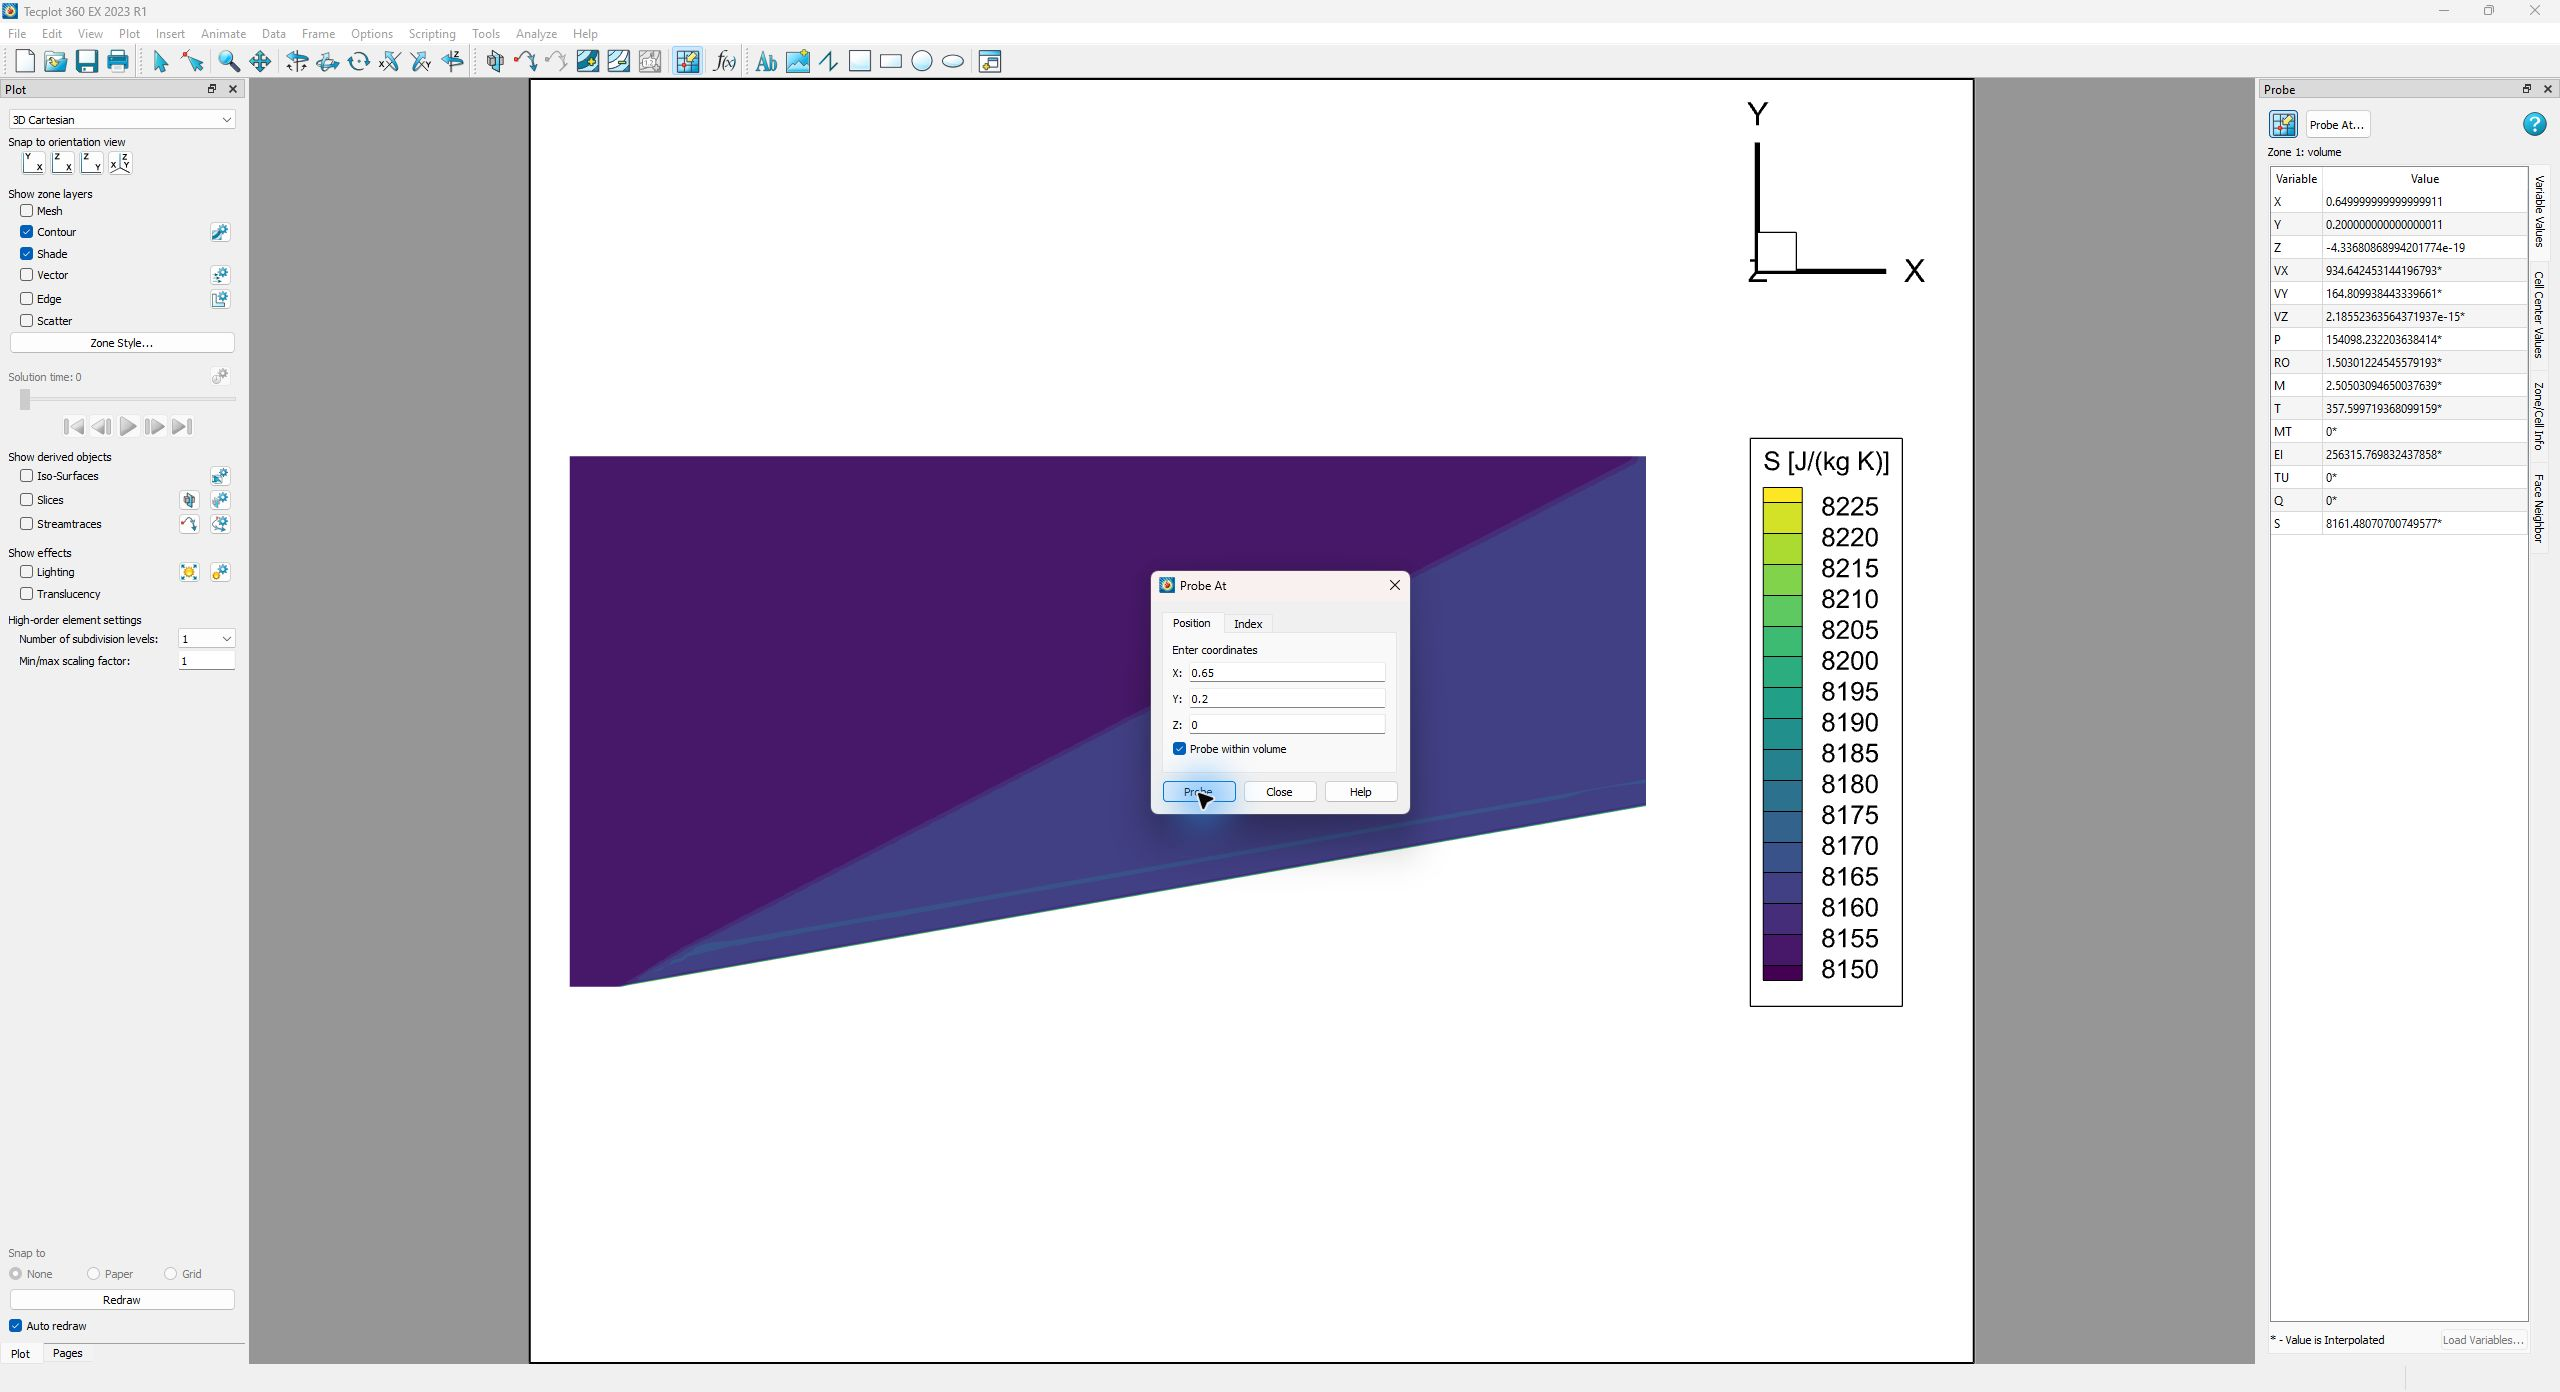

**Probe At: точка перед скачком.**

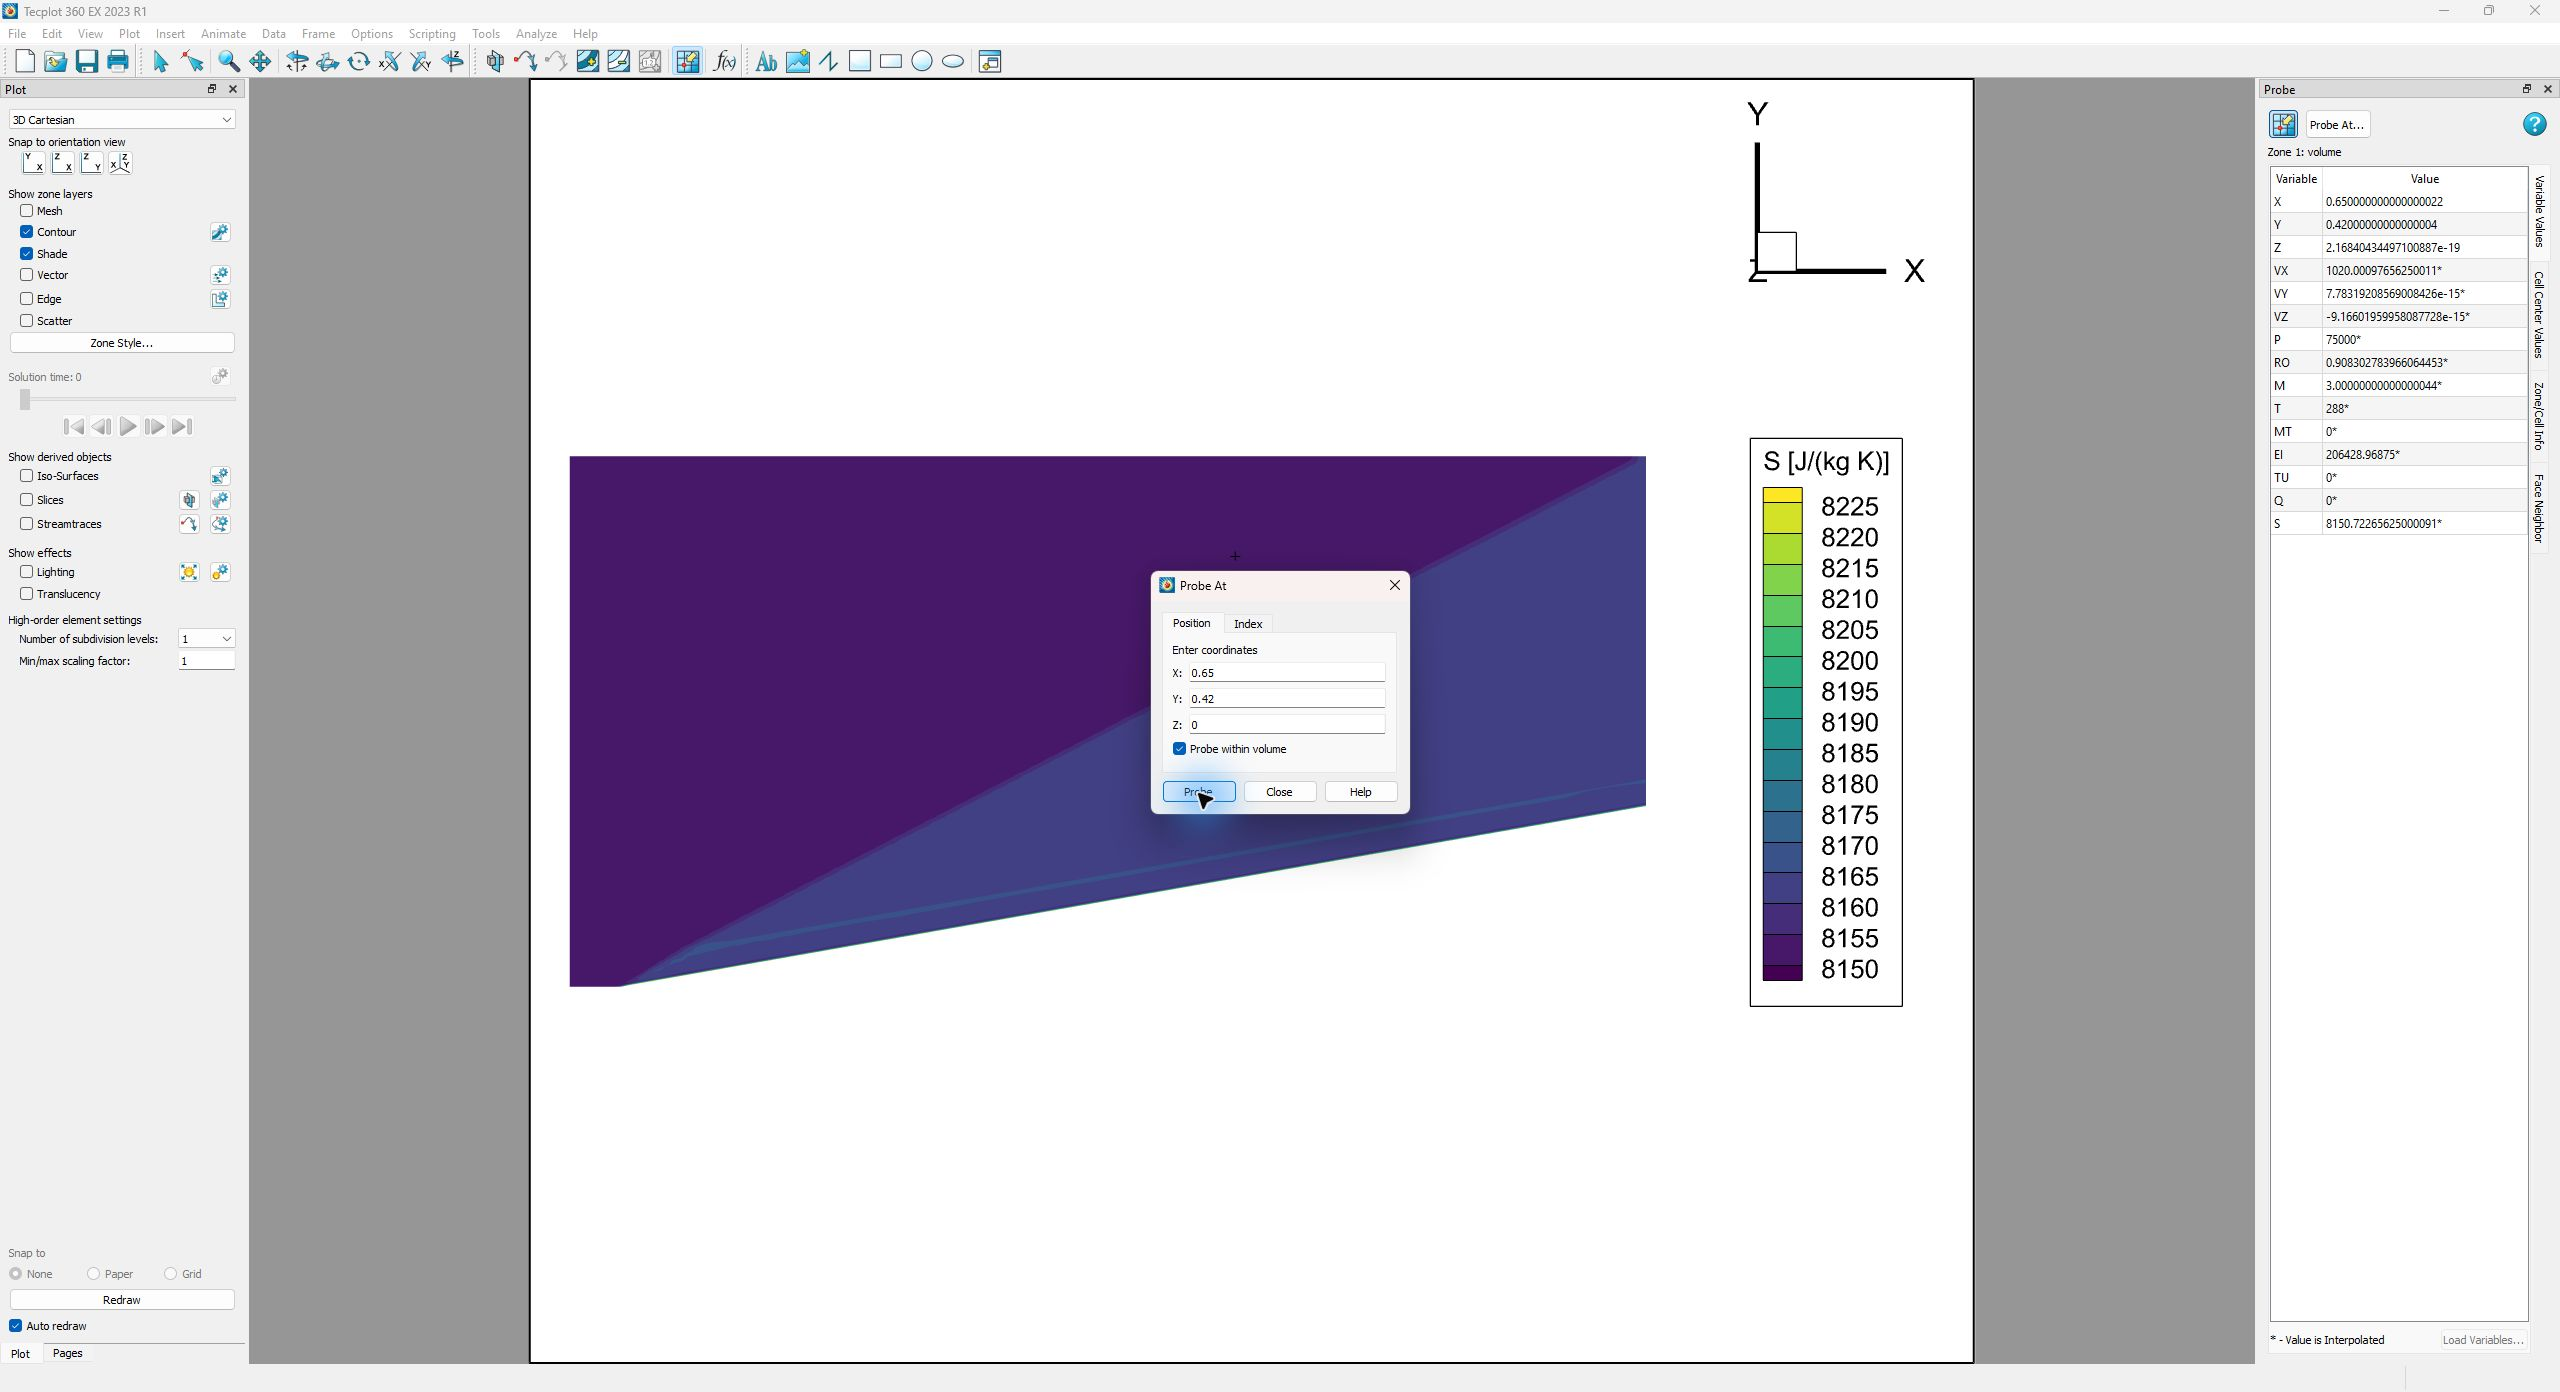

Параметр,Теория,Численный расчёт,"Погрешность, %"
"p₂, Па",154085.411,154098.232,0.0083205
"T₂, К",357.60442,357.599719,0.0013145
"ρ₂, кг/м³",1.50133202,1.50301225,0.1119156
M₂,2.50500068,2.50503095,0.0012082
"S₂, Дж/(кг·К)",8162.54442,8161.48071,0.0130316
"ΔS, Дж/(кг·К)",10.7955849,10.7580508,0.3476801
"θ, °",27.3826906,27.3694841,0.0482296


Результаты совпадают с проверенным отчётом; погрешности p, T, ρ, M и θ меньше 5 %.


In [13]:
probe = read_json('probe_values.json')
display(Markdown('**Probe At: точка за скачком.**'))
display(Image(filename=str(figures_path / 'stage_11.png'), width=1100))
display(Markdown('**Probe At: точка перед скачком.**'))
display(Image(filename=str(figures_path / 'stage_12.png'), width=1100))

probe_delta_S = probe['downstream']['S_J_kgK'] - probe['upstream']['S_J_kgK']
comparison_keys = ['P_Pa', 'T_K', 'rho_kg_m3', 'M', 'S_J_kgK',
                   'deltaS_J_kgK', 'shock_angle_deg']
labels = ['p₂, Па', 'T₂, К', 'ρ₂, кг/м³', 'M₂', 'S₂, Дж/(кг·К)',
          'ΔS, Дж/(кг·К)', 'θ, °']
theory_values = np.array([p2, T2, rho2, M2, S2, delta_S, theta_deg])
numerical_values = np.array([probe['downstream'][name] for name in comparison_keys[:5]]
                            + [probe_delta_S, theta_cfd])
errors_percent = np.abs(numerical_values - theory_values) / np.abs(theory_values) * 100

comparison_table = pd.DataFrame({
    'Параметр': labels, 'Теория': theory_values,
    'Численный расчёт': numerical_values, 'Погрешность, %': errors_percent,
})
display(comparison_table.style.format({
    'Теория': '{:.9g}', 'Численный расчёт': '{:.9g}', 'Погрешность, %': '{:.7f}'
}).hide(axis='index'))
comparison_table.to_csv(output_path / 'comparison.csv', index=False, encoding='utf-8-sig')

saved_comparison = read_json('comparison_probe.json')
for index, name in enumerate(comparison_keys):
    saved = saved_comparison[name]
    np.testing.assert_allclose(
        [theory_values[index], numerical_values[index], errors_percent[index]],
        [saved['analytic'], saved['numerical'], saved['relative_error_percent']],
        rtol=1e-6, atol=1e-8,
    )
assert probe_delta_S > 0
assert (errors_percent[[0, 1, 2, 3, 6]] < 5).all()
print('Результаты совпадают с проверенным отчётом; погрешности p, T, ρ, M и θ меньше 5 %.')

### Почему значение в ближайшей ячейке отличается от Probe At

Ближайший центр ячейки не совпадает с запрошенной точкой. Поля в файле являются
значениями ячеек, а Probe At отображает интерполированное значение.
Кроме того, энтропия нелинейно зависит от давления и плотности:

$$
\mathcal{I}\!\left[c_v\ln\!\left(\frac{p}{\rho^\gamma}\right)\right]
\ne c_v\ln\!\left(\frac{\mathcal{I}[p]}{\mathcal{I}[\rho]^\gamma}\right),
$$

где $\mathcal{I}$ обозначает интерполяцию. Поэтому нельзя смешивать значение энтропии
из одной процедуры с $p$ и $\rho$ из другой. В основной таблице сохранён согласованный
набор показаний Probe At. Ближайшие ячейки используются только как отдельная проверка
исходных полей и для выделения фронта скачка.

Малая разность двух значений условной энтропии около
$8.16\cdot10^3\,\mathrm{J/(kg\,K)}$ чувствительна к способу выборки.
Это ограничивает выводы по одной контрольной точке.

In [14]:
cell_delta_S = down['S'] - up['S']
delta_table = pd.DataFrame({
    'Способ': ['Теория', 'Tecplot Probe At', 'Ближайшие центры ячеек'],
    'S₁, Дж/(кг·К)': [S1, probe['upstream']['S_J_kgK'], up['S']],
    'S₂, Дж/(кг·К)': [S2, probe['downstream']['S_J_kgK'], down['S']],
    'ΔS, Дж/(кг·К)': [delta_S, probe_delta_S, cell_delta_S],
    'Погрешность ΔS, %': [0, abs(probe_delta_S - delta_S) / delta_S * 100,
                           abs(cell_delta_S - delta_S) / delta_S * 100],
})
display(delta_table.style.format({name: '{:.8f}' for name in delta_table.columns[1:]})
        .hide(axis='index'))
display(pd.DataFrame({
    'Точка': ['Перед скачком', 'За скачком'],
    'Индекс ячейки (с 0)': [up_index, down_index],
    'x центра, м': centres[[up_index, down_index], 0],
    'y центра, м': centres[[up_index, down_index], 1],
}).style.format({'x центра, м': '{:.9f}', 'y центра, м': '{:.9f}'}).hide(axis='index'))

Способ,"S₁, Дж/(кг·К)","S₂, Дж/(кг·К)","ΔS, Дж/(кг·К)","Погрешность ΔS, %"
Теория,8151.74883437,8162.54441923,10.79558486,0.00000000
Tecplot Probe At,8150.72265625,8161.48070701,10.75805076,0.34768011
Ближайшие центры ячеек,8150.72244811,8162.14953690,11.42708879,5.84965003


Точка,Индекс ячейки (с 0),"x центра, м","y центра, м"
Перед скачком,15373,0.652496891,0.420461611
За скачком,10768,0.652125260,0.200136766


## 9. Невязка и сходимость

В `residuals.csv` сохранены 200 отсчётов через 100 итераций, вплоть до 20 000.
Анализируется невязка EPT, обозначенная так в журнале решателя.
Число её значащих цифр ограничено исходным экспортом.

Уменьшение невязки оценивается отношением
$K_{\mathrm{drop}}=\mathrm{EPT}_{100}/\mathrm{EPT}_{20000}$.
График строится с логарифмической вертикальной шкалой. Интервал $18000\leq n\leq20000$
показывает оставшиеся колебания. Из одного конечного значения невязки нельзя заключить,
что все поля строго стационарны.

Показатель,Значение
EPT на итерации 100,0.01077
EPT на итерации 20 000,5.089e-05
"Уменьшение, раз",211.63293
Минимум за весь расчёт,3.834e-05
Минимум на 18 000–20 000,4.248e-05
Максимум на 18 000–20 000,0.0001259


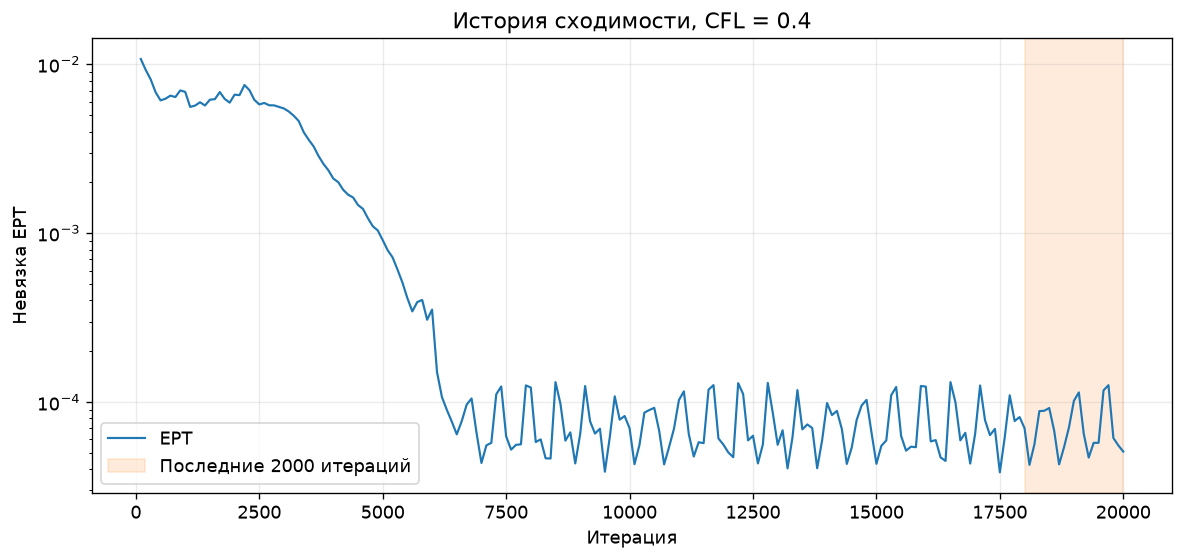

In [15]:
residuals = pd.read_csv(data_path / 'residuals.csv')
iteration = residuals['iteration'].to_numpy()
ept = residuals['EPT'].to_numpy()
assert len(iteration) == 200 and iteration[-1] == 20000
assert (np.diff(iteration) == 100).all() and (ept > 0).all()
tail = ept[iteration >= 18000]
drop_factor = ept[0] / ept[-1]

display(pd.DataFrame({
    'Показатель': ['EPT на итерации 100', 'EPT на итерации 20 000',
                   'Уменьшение, раз', 'Минимум за весь расчёт',
                   'Минимум на 18 000–20 000', 'Максимум на 18 000–20 000'],
    'Значение': [ept[0], ept[-1], drop_factor, ept.min(), tail.min(), tail.max()],
}).style.format({'Значение': '{:.8g}'}).hide(axis='index'))

fig, ax = plt.subplots()
ax.semilogy(iteration, ept, linewidth=1.3, label='EPT')
ax.axvspan(18000, 20000, color='tab:orange', alpha=0.15, label='Последние 2000 итераций')
ax.set(xlabel='Итерация', ylabel='Невязка EPT', title='История сходимости, CFL = 0.4')
ax.legend()
fig.tight_layout()
fig.savefig(output_path / 'residuals.png', dpi=180)
plt.show()

## 10. Выводы и границы проверки

Получен присоединённый косой скачок слабой ветви. Газ сжимается и нагревается,
число Маха уменьшается, но за скачком остаётся больше единицы. Приращение энтропии положительно.
Измеренный по давлению угол и значения Probe At согласуются с аналитическим решением;
погрешности требуемых параметров меньше 5 %.

Невязка уменьшилась примерно в 212 раз, однако на последних итерациях сохраняются колебания.
Выполнен один расчёт на одной сетке и при одном CFL. Поэтому влияние размера ячеек,
числа итераций и CFL не исследовано количественно; сеточная независимость не доказана.
Методичка не требует серии сеток, но без неё нельзя оценить погрешность дискретизации
или утверждать, что дальнейшее сгущение сетки и продолжение расчёта не изменят результат.

Тонкий пограничный слой и фронт скачка чувствительны к сетке. Различие газовых постоянных
аналитического эталона и экспорта, а также способ получения точечных значений учтены выше.
Положительный результат сравнения относится к указанной контрольной точке и выбранному
способу измерения угла, а не к любой точке области.

Последняя ячейка ещё раз проверяет неизменность входных файлов и сохраняет рассчитанные
таблицы и краткий итог в `output`. Она не перезаписывает исходные данные отчёта.

In [16]:
for name, expected_hash in manifest.items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest() == expected_hash

summary = {
    'variant': 9,
    'author': 'Жуховицкий Александр Дмитриевич',
    'group': 'М8О-403Б-23',
    'nodes': nodes,
    'cells': cells_count,
    'analytic': analytic,
    'theta_cfd_deg': theta_cfd,
    'comparison': comparison_table.to_dict(orient='records'),
    'R_field_J_kgK': R_field,
    'deltaS_nearest_cells_J_kgK': cell_delta_S,
    'residual_last': float(ept[-1]),
    'residual_drop_factor': float(drop_factor),
    'source_hashes_unchanged': True,
}
(output_path / 'notebook_results.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8'
)
display(Math(r'\theta_{\mathrm{theory}}=' + f'{theta_deg:.5f}'
             + r'^\circ,\qquad\theta_{\mathrm{CFD}}=' + f'{theta_cfd:.5f}' + r'^\circ'))
display(Math(r'\Delta S_{\mathrm{Probe}}=' + f'{probe_delta_S:.6f}'
             + r'\,\mathrm{J/(kg\,K)}>0'))
print('Все проверки пройдены. Входные файлы не изменены. Результаты сохранены в output.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Все проверки пройдены. Входные файлы не изменены. Результаты сохранены в output.
